# Data exploration

First look at the order books, trades and price dynamics for each product.

# IMC Prosperity — Analysis Notebook
Clean, reusable analysis for every round.

**How to use:**
1. Put `prosperity_analysis.py` in the same directory as this notebook.
2. Put your CSV files in a subfolder (e.g. `data/`).
3. Run cells top-to-bottom. Every time you add a new day file, re-run the loader cells — everything updates automatically.


## 0 · Imports

In [1]:
import sys
sys.path.insert(0, './')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
%matplotlib inline

import importlib
import prosperity_analysis
importlib.reload(prosperity_analysis)

from prosperity_analysis import *

import plotly.io as pio
pio.renderers.default = "notebook_connected"

from prosperity_analysis import (
    load_prices, load_trades, debug_files,
    get_products, enrich, enrich_spread, compute_spread,
    plot_price_evolution, plot_bid_ask_spread, plot_zscore_velocity,
    plot_spread, plot_spread_zscore, spread_stats,
    compare_editions, compare_spread_editions,
    overview, match_product_across_editions,
)


## 1 · Load Data

Point `DATA_FOLDER` at the directory that contains your CSV files.
The loaders auto-detect every matching file — just drop a new one in
and re-run this cell.


In [2]:
# ── Folder layout ───────────────────────────────────────────────
#   Prices/                  ← current year files (auto-detected)
#   Prices/P1/               ← Prosperity 1
#   Prices/P2/               ← Prosperity 2
#   Prices/P3/               ← Prosperity 3
# ────────────────────────────────────────────────────────────────

# If anything fails, uncomment this to see exactly what files are found:
# debug_files("Prices")

# Current year
df = load_prices("DATA_DIR")
df_trade = load_trades("DATA_DIR")   # returns empty DataFrame if no trade files found

# Previous years (uncomment as you add folders)
# df_p1 = load_prices("Prices", edition="P1")
# df_p2 = load_prices("Prices", edition="P2")
df_p3 = load_prices("Prices", edition="P3")

print("Products this year:", get_products(df))
print(f"Price rows : {len(df):,}")
print(f"Trade rows : {len(df_trade):,}")


Products this year: ['GALAXY_SOUNDS_BLACK_HOLES', 'GALAXY_SOUNDS_DARK_MATTER', 'GALAXY_SOUNDS_PLANETARY_RINGS', 'GALAXY_SOUNDS_SOLAR_FLAMES', 'GALAXY_SOUNDS_SOLAR_WINDS', 'HYDROGEL_PACK', 'MICROCHIP_CIRCLE', 'MICROCHIP_OVAL', 'MICROCHIP_RECTANGLE', 'MICROCHIP_SQUARE', 'MICROCHIP_TRIANGLE', 'OXYGEN_SHAKE_CHOCOLATE', 'OXYGEN_SHAKE_EVENING_BREATH', 'OXYGEN_SHAKE_GARLIC', 'OXYGEN_SHAKE_MINT', 'OXYGEN_SHAKE_MORNING_BREATH', 'PANEL_1X2', 'PANEL_1X4', 'PANEL_2X2', 'PANEL_2X4', 'PANEL_4X4', 'PEBBLES_L', 'PEBBLES_M', 'PEBBLES_S', 'PEBBLES_XL', 'PEBBLES_XS', 'ROBOT_DISHES', 'ROBOT_IRONING', 'ROBOT_LAUNDRY', 'ROBOT_MOPPING', 'ROBOT_VACUUMING', 'SLEEP_POD_COTTON', 'SLEEP_POD_LAMB_WOOL', 'SLEEP_POD_NYLON', 'SLEEP_POD_POLYESTER', 'SLEEP_POD_SUEDE', 'SNACKPACK_CHOCOLATE', 'SNACKPACK_PISTACHIO', 'SNACKPACK_RASPBERRY', 'SNACKPACK_STRAWBERRY', 'SNACKPACK_VANILLA', 'TRANSLATOR_ASTRO_BLACK', 'TRANSLATOR_ECLIPSE_CHARCOAL', 'TRANSLATOR_GRAPHITE_MIST', 'TRANSLATOR_SPACE_GRAY', 'TRANSLATOR_VOID_BLUE', 'UV_VIS

## 2 · Dataset Overview

Products   : ['GALAXY_SOUNDS_BLACK_HOLES', 'GALAXY_SOUNDS_DARK_MATTER', 'GALAXY_SOUNDS_PLANETARY_RINGS', 'GALAXY_SOUNDS_SOLAR_FLAMES', 'GALAXY_SOUNDS_SOLAR_WINDS', 'HYDROGEL_PACK', 'MICROCHIP_CIRCLE', 'MICROCHIP_OVAL', 'MICROCHIP_RECTANGLE', 'MICROCHIP_SQUARE', 'MICROCHIP_TRIANGLE', 'OXYGEN_SHAKE_CHOCOLATE', 'OXYGEN_SHAKE_EVENING_BREATH', 'OXYGEN_SHAKE_GARLIC', 'OXYGEN_SHAKE_MINT', 'OXYGEN_SHAKE_MORNING_BREATH', 'PANEL_1X2', 'PANEL_1X4', 'PANEL_2X2', 'PANEL_2X4', 'PANEL_4X4', 'PEBBLES_L', 'PEBBLES_M', 'PEBBLES_S', 'PEBBLES_XL', 'PEBBLES_XS', 'ROBOT_DISHES', 'ROBOT_IRONING', 'ROBOT_LAUNDRY', 'ROBOT_MOPPING', 'ROBOT_VACUUMING', 'SLEEP_POD_COTTON', 'SLEEP_POD_LAMB_WOOL', 'SLEEP_POD_NYLON', 'SLEEP_POD_POLYESTER', 'SLEEP_POD_SUEDE', 'SNACKPACK_CHOCOLATE', 'SNACKPACK_PISTACHIO', 'SNACKPACK_RASPBERRY', 'SNACKPACK_STRAWBERRY', 'SNACKPACK_VANILLA', 'TRANSLATOR_ASTRO_BLACK', 'TRANSLATOR_ECLIPSE_CHARCOAL', 'TRANSLATOR_GRAPHITE_MIST', 'TRANSLATOR_SPACE_GRAY', 'TRANSLATOR_VOID_BLUE', 'UV_VISOR_AMBE

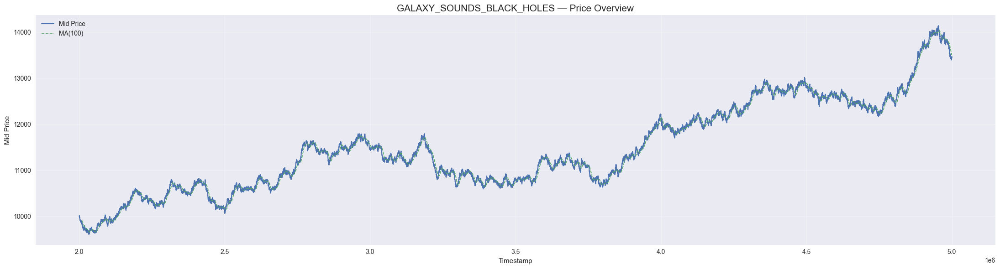

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10680.49,10673.69,10687.29
2,first half,10272.35,10265.79,10278.92
2,second half,11088.63,11081.59,11095.66
3,full day,11107.88,11100.84,11114.92
3,first half,11065.09,11058.08,11072.1
3,second half,11150.67,11143.59,11157.75
4,full day,12612.25,12604.32,12620.17
4,first half,12354.4,12346.62,12362.17
4,second half,12870.1,12862.02,12878.17



GALAXY_SOUNDS_DARK_MATTER


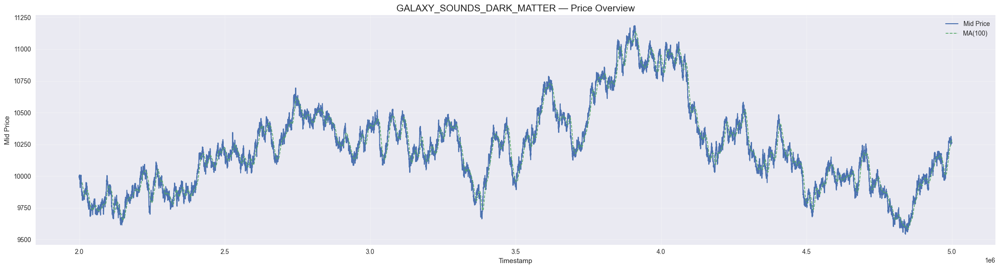

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10111.91,10105.45,10118.38
2,first half,9907.37,9901.03,9913.72
2,second half,10316.45,10309.88,10323.03
3,full day,10421.95,10415.31,10428.59
3,first half,10217.53,10211.02,10224.04
3,second half,10626.37,10619.6,10633.15
4,full day,10146.12,10139.65,10152.59
4,first half,10360.66,10354.06,10367.26
4,second half,9931.58,9925.24,9937.93



GALAXY_SOUNDS_PLANETARY_RINGS


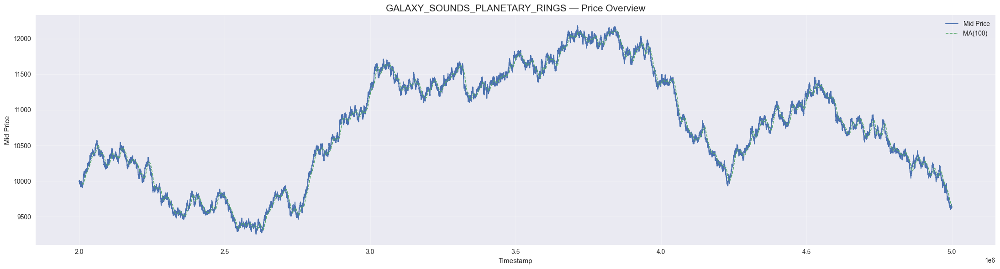

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10013.25,10006.84,10019.66
2,first half,9980.68,9974.29,9987.08
2,second half,10045.82,10039.4,10052.25
3,full day,11615.27,11607.93,11622.62
3,first half,11406.74,11399.54,11413.95
3,second half,11823.8,11816.32,11831.28
4,full day,10671.49,10664.71,10678.28
4,first half,10736.21,10729.39,10743.02
4,second half,10606.78,10600.04,10613.53



GALAXY_SOUNDS_SOLAR_FLAMES


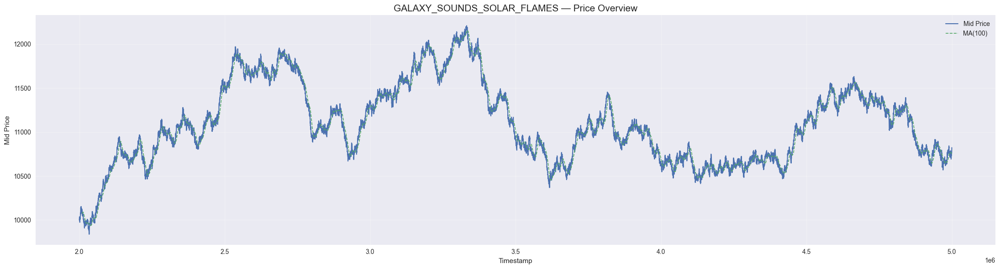

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,11095.64,11088.6,11102.69
2,first half,10763.8,10756.94,10770.66
2,second half,11427.49,11420.25,11434.72
3,full day,11260.0,11252.86,11267.13
3,first half,11626.49,11619.15,11633.83
3,second half,10893.51,10886.58,10900.44
4,full day,10922.07,10915.15,10929.0
4,first half,10673.79,10667.01,10680.57
4,second half,11170.36,11163.28,11177.43



GALAXY_SOUNDS_SOLAR_WINDS


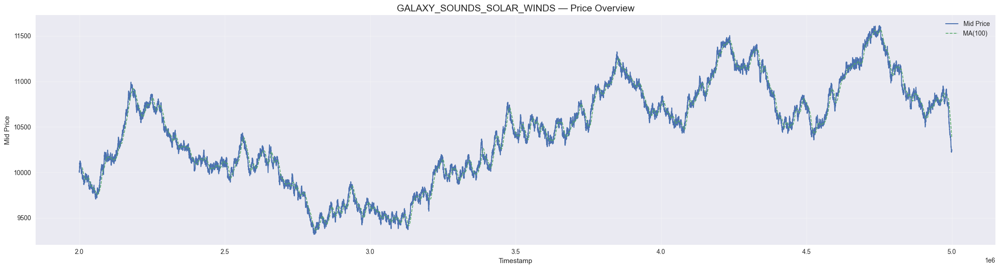

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10066.58,10060.15,10073.02
2,first half,10299.91,10293.33,10306.5
2,second half,9833.25,9826.96,9839.54
3,full day,10309.85,10303.28,10316.43
3,first half,9918.06,9911.73,9924.39
3,second half,10701.64,10694.82,10708.47
4,full day,10936.2,10929.26,10943.14
4,first half,10914.47,10907.54,10921.4
4,second half,10957.92,10950.97,10964.87



HYDROGEL_PACK


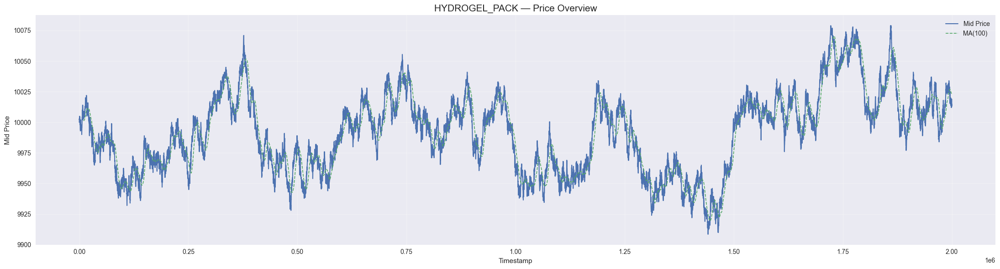

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,9990.96,9983.11,9998.81
0,first half,9984.7,9976.85,9992.55
0,second half,9997.23,9989.37,10005.08
1,full day,9992.06,9984.19,9999.92
1,first half,9962.8,9954.95,9970.65
1,second half,10021.31,10013.43,10029.18



MICROCHIP_CIRCLE


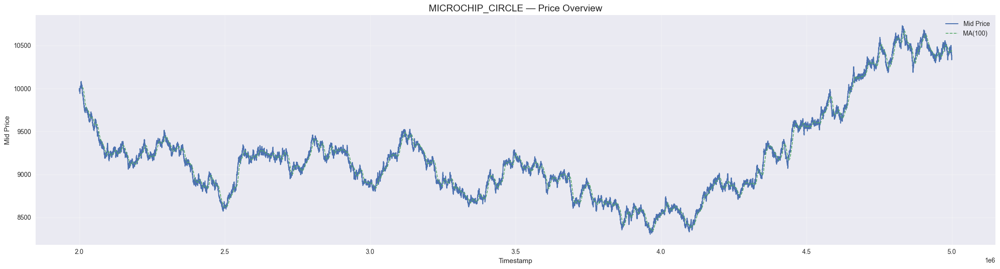

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9190.4,9186.27,9194.53
2,first half,9231.25,9227.1,9235.4
2,second half,9149.56,9145.45,9153.67
3,full day,8897.68,8893.68,8901.68
3,first half,9026.7,9022.65,9030.74
3,second half,8768.67,8764.72,8772.63
4,full day,9556.57,9552.3,9560.83
4,first half,8928.41,8924.41,8932.42
4,second half,10184.72,10180.2,10189.25



MICROCHIP_OVAL


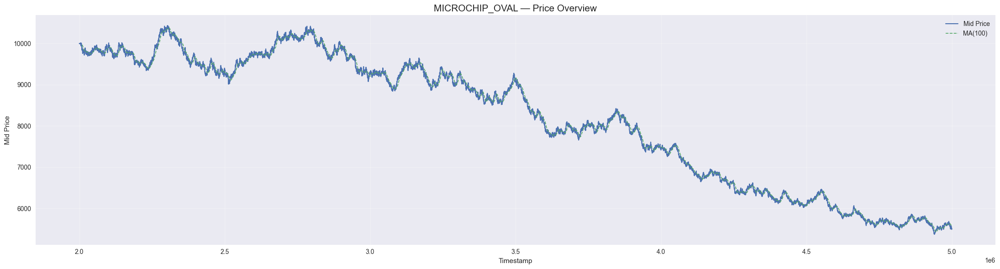

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9766.38,9762.02,9770.74
2,first half,9745.61,9741.26,9749.97
2,second half,9787.15,9782.79,9791.51
3,full day,8543.77,8539.91,8547.64
3,first half,9073.23,9069.16,9077.3
3,second half,8014.32,8010.66,8017.98
4,full day,6228.64,6225.69,6231.59
4,first half,6654.15,6651.04,6657.26
4,second half,5803.13,5800.34,5805.93



MICROCHIP_RECTANGLE


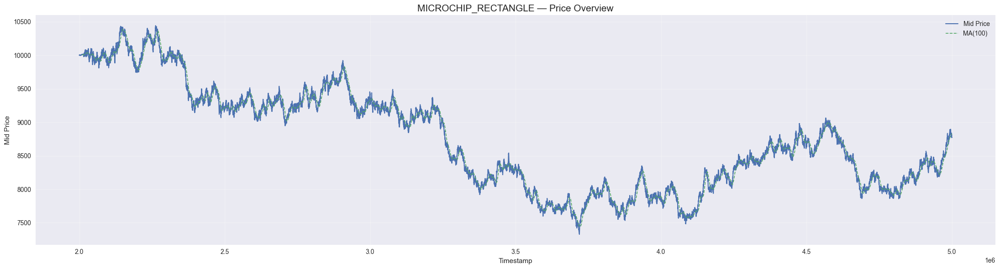

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9596.87,9592.58,9601.16
2,first half,9861.2,9856.8,9865.6
2,second half,9332.55,9328.37,9336.72
3,full day,8293.35,8289.59,8297.12
3,first half,8734.59,8730.65,8738.52
3,second half,7852.12,7848.52,7855.71
4,full day,8307.09,8303.32,8310.87
4,first half,8245.92,8242.18,8249.67
4,second half,8368.26,8364.45,8372.07



MICROCHIP_SQUARE


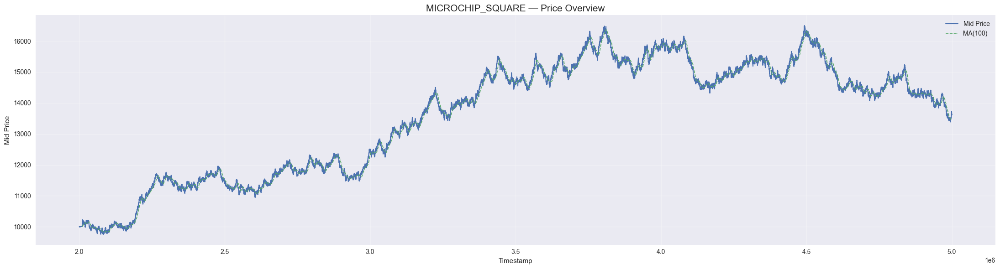

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,11268.46,11263.51,11273.41
2,first half,10850.49,10845.7,10855.28
2,second half,11686.43,11681.32,11691.54
3,full day,14584.24,14578.0,14590.48
3,first half,13823.53,13817.59,13829.47
3,second half,15344.95,15338.4,15351.5
4,full day,14931.54,14925.16,14937.93
4,first half,15224.07,15217.58,15230.56
4,second half,14639.02,14632.74,14645.29



MICROCHIP_TRIANGLE


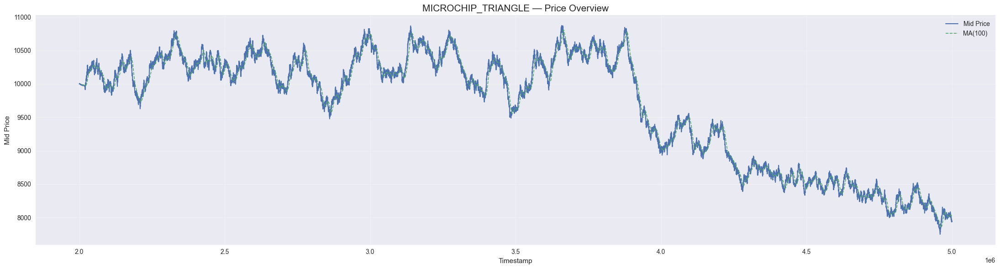

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10216.49,10211.96,10221.03
2,first half,10230.58,10226.03,10235.12
2,second half,10202.41,10197.89,10206.93
3,full day,10229.08,10224.56,10233.61
3,first half,10266.72,10262.18,10271.26
3,second half,10191.45,10186.94,10195.96
4,full day,8613.6,8609.7,8617.49
4,first half,8911.52,8907.52,8915.53
4,second half,8315.67,8311.89,8319.45



OXYGEN_SHAKE_CHOCOLATE


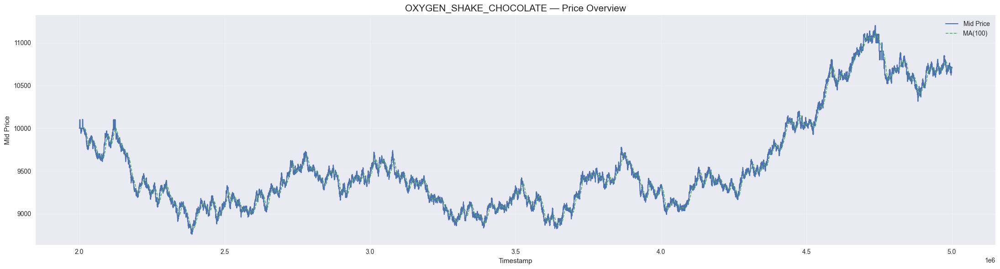

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9355.81,9349.9,9361.72
2,first half,9380.03,9374.12,9385.95
2,second half,9331.58,9325.68,9337.48
3,full day,9243.59,9237.64,9249.53
3,first half,9217.59,9211.68,9223.5
3,second half,9269.58,9263.61,9275.55
4,full day,10071.24,10064.82,10077.67
4,first half,9493.77,9487.68,9499.86
4,second half,10648.72,10641.95,10655.48



OXYGEN_SHAKE_EVENING_BREATH


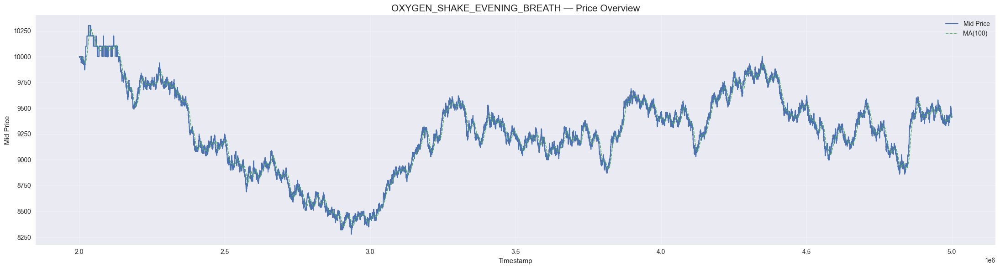

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9184.56,9178.56,9190.56
2,first half,9671.36,9665.26,9677.46
2,second half,8697.77,8691.87,8703.66
3,full day,9204.29,9198.39,9210.19
3,first half,9145.71,9139.82,9151.6
3,second half,9262.88,9256.97,9268.79
4,full day,9426.83,9420.93,9432.72
4,first half,9560.35,9554.45,9566.24
4,second half,9293.31,9287.42,9299.21



OXYGEN_SHAKE_GARLIC


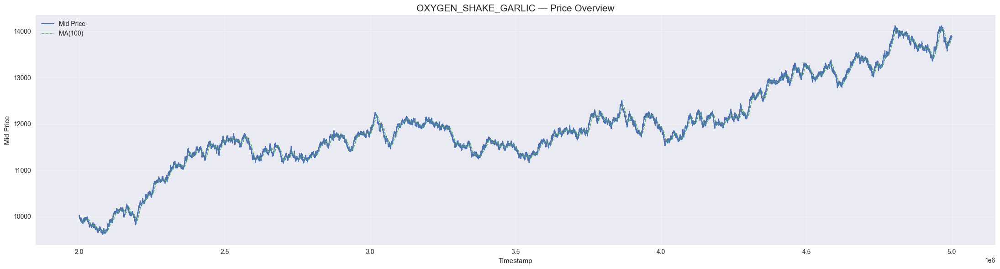

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,11058.25,11051.23,11065.27
2,first half,10606.7,10599.94,10613.47
2,second half,11509.79,11502.51,11517.07
3,full day,11807.84,11800.39,11815.3
3,first half,11757.46,11750.05,11764.87
3,second half,11858.22,11850.72,11865.72
4,full day,12910.83,12902.73,12918.93
4,first half,12361.75,12353.97,12369.54
4,second half,13459.91,13451.48,13468.33



OXYGEN_SHAKE_MINT


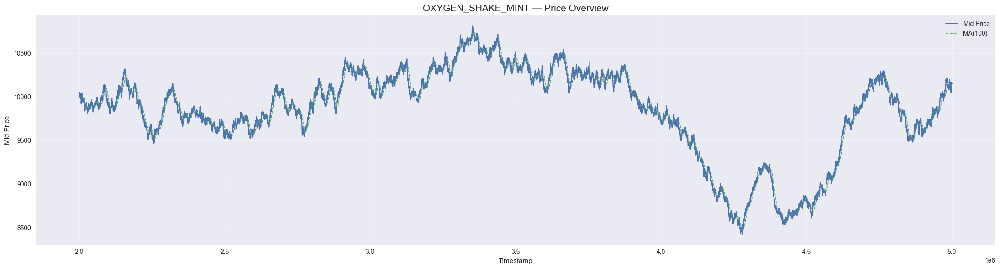

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9893.52,9887.18,9899.85
2,first half,9858.86,9852.54,9865.18
2,second half,9928.18,9921.82,9934.53
3,full day,10265.45,10258.9,10272.0
3,first half,10341.12,10334.54,10347.71
3,second half,10189.78,10183.26,10196.3
4,full day,9356.21,9350.21,9362.22
4,first half,9047.72,9041.9,9053.55
4,second half,9664.7,9658.52,9670.89



OXYGEN_SHAKE_MORNING_BREATH


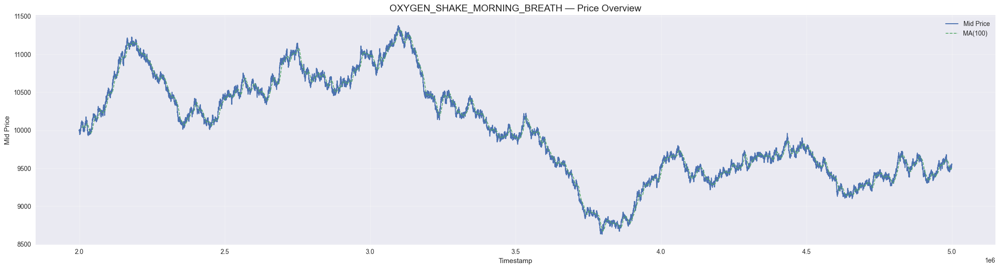

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10584.24,10577.5,10590.99
2,first half,10477.23,10470.54,10483.92
2,second half,10691.26,10684.46,10698.06
3,full day,9911.14,9904.8,9917.47
3,first half,10515.33,10508.65,10522.01
3,second half,9306.95,9300.96,9312.94
4,full day,9505.98,9499.88,9512.07
4,first half,9581.17,9575.03,9587.31
4,second half,9430.78,9424.74,9436.83



PANEL_1X2


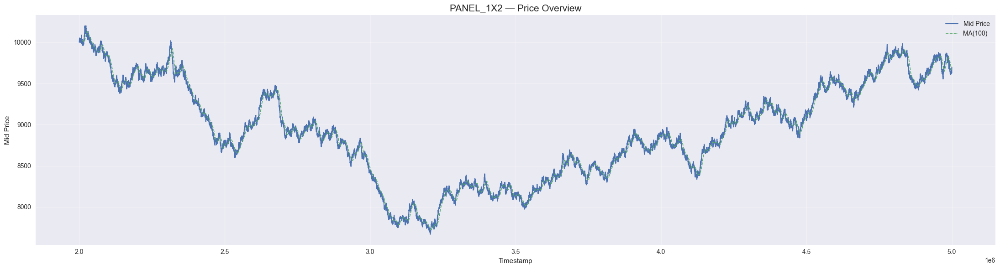

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9231.6,9225.66,9237.55
2,first half,9549.68,9543.54,9555.82
2,second half,8913.52,8907.77,8919.27
3,full day,8280.93,8275.55,8286.3
3,first half,8076.21,8070.97,8081.45
3,second half,8485.65,8480.14,8491.15
4,full day,9255.66,9249.71,9261.61
4,first half,8925.94,8920.18,8931.69
4,second half,9585.38,9579.24,9591.52



PANEL_1X4


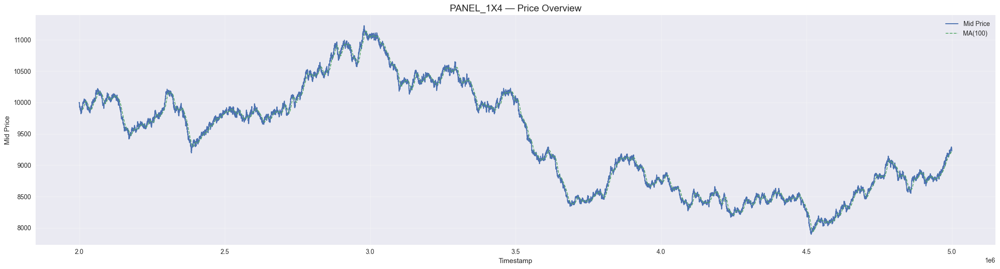

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10022.36,10017.92,10026.8
2,first half,9788.88,9784.53,9793.23
2,second half,10255.84,10251.31,10260.36
3,full day,9632.6,9628.32,9636.87
3,first half,10357.76,10353.2,10362.31
3,second half,8907.43,8903.43,8911.44
4,full day,8537.79,8533.94,8541.64
4,first half,8467.14,8463.32,8470.97
4,second half,8608.43,8604.56,8612.31



PANEL_2X2


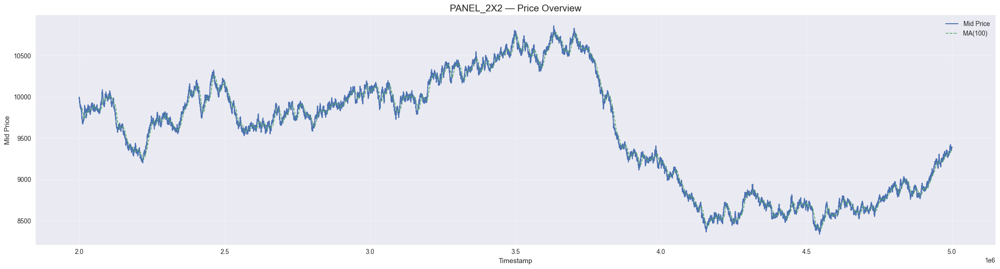

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9806.89,9802.54,9811.25
2,first half,9786.92,9782.57,9791.28
2,second half,9826.86,9822.51,9831.22
3,full day,10167.06,10162.57,10171.55
3,first half,10228.69,10224.18,10233.2
3,second half,10105.44,10100.97,10109.91
4,full day,8755.84,8751.91,8759.77
4,first half,8711.72,8707.8,8715.63
4,second half,8799.97,8796.02,8803.91



PANEL_2X4


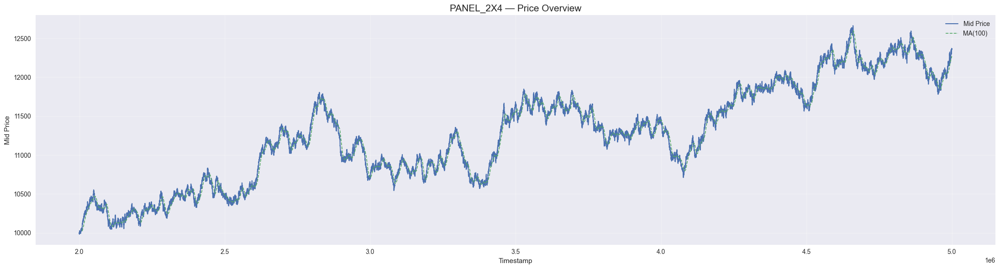

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10713.54,10708.83,10718.25
2,first half,10368.72,10364.14,10373.3
2,second half,11058.36,11053.53,11063.2
3,full day,11206.92,11202.03,11211.82
3,first half,10939.43,10934.65,10944.21
3,second half,11474.42,11469.41,11479.43
4,full day,11875.65,11870.5,11880.81
4,first half,11562.83,11557.79,11567.86
4,second half,12188.48,12183.2,12193.76



PANEL_4X4


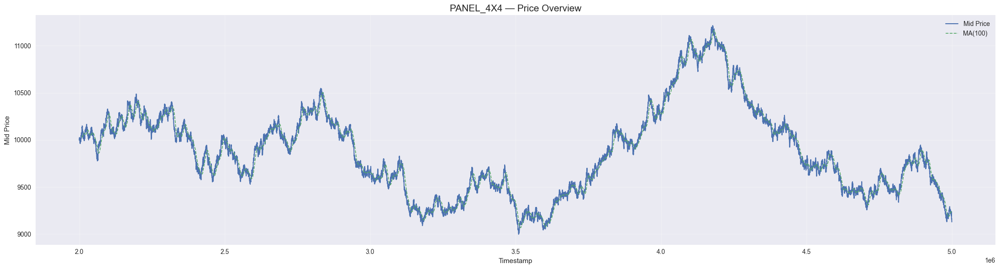

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10040.12,10035.67,10044.57
2,first half,10074.06,10069.59,10078.53
2,second half,10006.18,10001.76,10010.61
3,full day,9548.04,9543.79,9552.28
3,first half,9448.18,9443.99,9452.38
3,second half,9647.89,9643.6,9652.18
4,full day,10048.0,10043.56,10052.43
4,first half,10517.7,10513.08,10522.32
4,second half,9578.3,9574.05,9582.55



PEBBLES_L


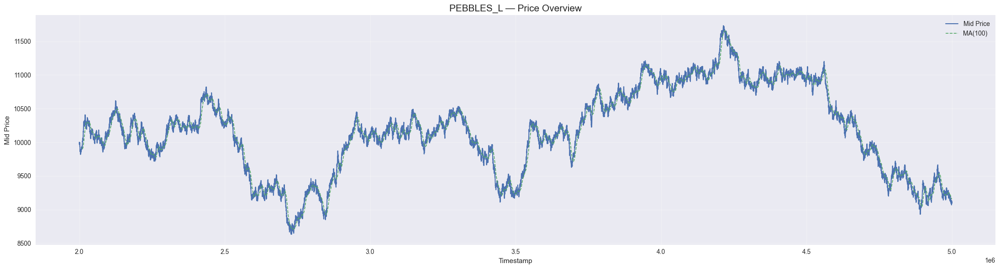

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9862.81,9856.49,9869.13
2,first half,10210.38,10203.86,10216.91
2,second half,9515.24,9509.12,9521.35
3,full day,10201.45,10194.93,10207.98
3,first half,10022.69,10016.27,10029.11
3,second half,10380.22,10373.58,10386.85
4,full day,10458.07,10451.39,10464.75
4,first half,11037.31,11030.28,11044.33
4,second half,9878.83,9872.49,9885.16



PEBBLES_M


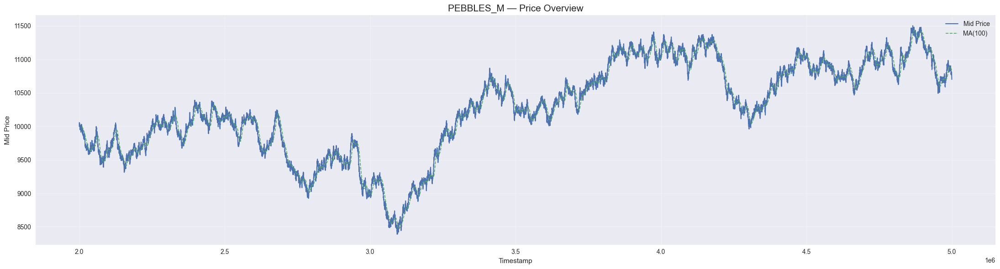

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9747.45,9741.19,9753.7
2,first half,9883.52,9877.19,9889.86
2,second half,9611.37,9605.19,9617.54
3,full day,10170.49,10163.98,10177.0
3,first half,9677.3,9671.08,9683.51
3,second half,10663.69,10656.89,10670.49
4,full day,10871.79,10864.87,10878.71
4,first half,10801.78,10794.9,10808.66
4,second half,10941.81,10934.85,10948.76



PEBBLES_S


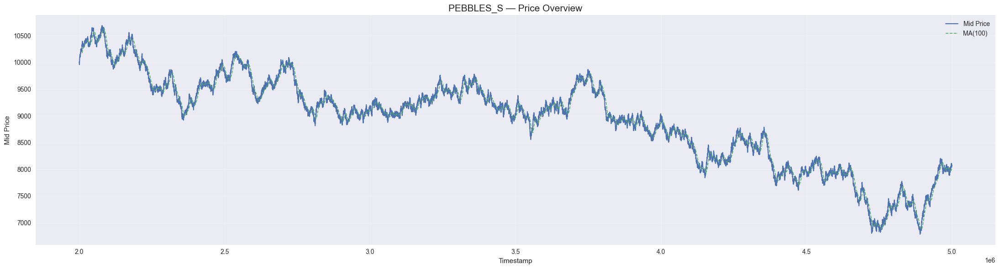

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9650.48,9644.28,9656.68
2,first half,9856.47,9850.15,9862.79
2,second half,9444.49,9438.41,9450.57
3,full day,9197.52,9191.58,9203.45
3,first half,9282.17,9276.19,9288.16
3,second half,9112.86,9106.98,9118.74
4,full day,7949.07,7943.88,7954.27
4,first half,8304.48,8299.08,8309.89
4,second half,7593.66,7588.68,7598.64



PEBBLES_XL


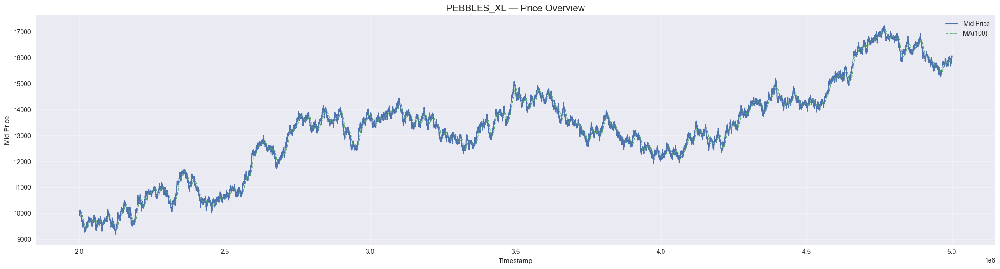

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,11549.77,11542.44,11557.09
2,first half,10367.18,10360.56,10373.8
2,second half,12732.36,12724.33,12740.38
3,full day,13462.1,13453.64,13470.55
3,first half,13468.98,13460.51,13477.44
3,second half,13455.21,13446.76,13463.66
4,full day,14664.9,14655.74,14674.07
4,first half,13483.46,13474.99,13491.93
4,second half,15846.35,15836.49,15856.22



PEBBLES_XS


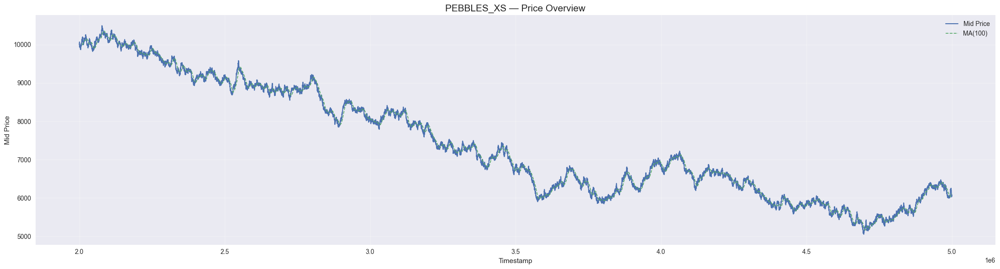

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9189.41,9183.48,9195.33
2,first half,9682.41,9676.19,9688.62
2,second half,8696.41,8690.77,8702.04
3,full day,6968.41,6963.79,6973.03
3,first half,7548.79,7543.83,7553.76
3,second half,6388.03,6383.76,6392.3
4,full day,6056.1,6052.03,6060.18
4,first half,6372.93,6368.67,6377.2
4,second half,5739.28,5735.39,5743.16



ROBOT_DISHES


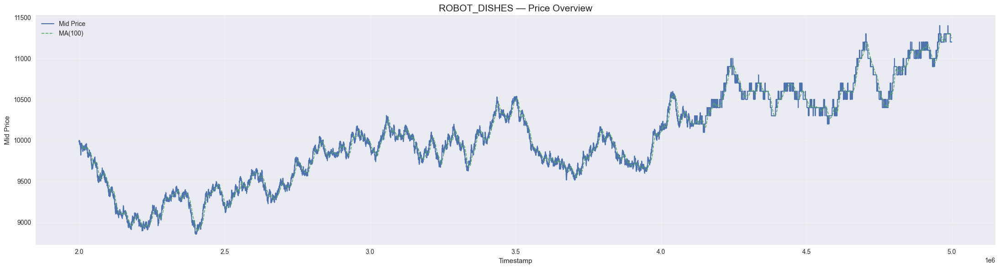

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9472.68,9469.21,9476.16
2,first half,9287.69,9284.27,9291.11
2,second half,9657.68,9654.15,9661.21
3,full day,9944.13,9940.49,9947.77
3,first half,10031.22,10027.58,10034.87
3,second half,9857.03,9853.4,9860.67
4,full day,10638.13,10634.22,10642.04
4,first half,10486.46,10482.57,10490.34
4,second half,10789.8,10785.88,10793.73



ROBOT_IRONING


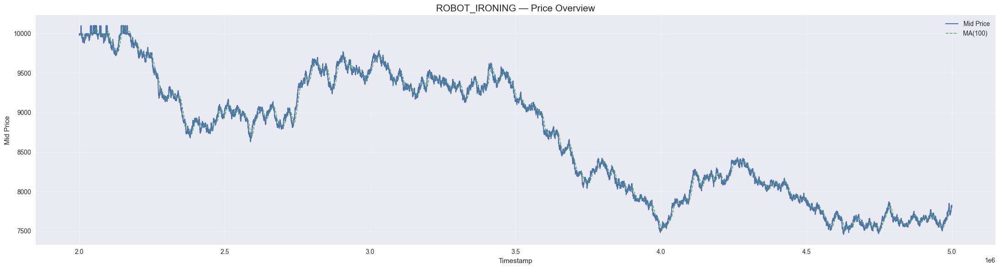

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9354.29,9350.86,9357.72
2,first half,9473.2,9469.71,9476.69
2,second half,9235.38,9232.02,9238.74
3,full day,8892.57,8889.35,8895.78
3,first half,9406.98,9403.5,9410.45
3,second half,8378.16,8375.21,8381.12
4,full day,7857.85,7854.9,7860.8
4,first half,8068.0,8065.05,8070.95
4,second half,7647.7,7644.76,7650.65



ROBOT_LAUNDRY


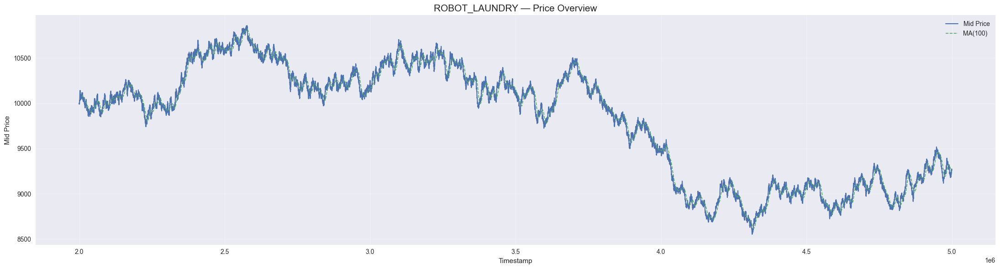

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10273.57,10269.85,10277.3
2,first half,10170.86,10167.17,10174.56
2,second half,10376.29,10372.53,10380.04
3,full day,10164.65,10160.96,10168.34
3,first half,10356.72,10352.98,10360.46
3,second half,9972.59,9968.95,9976.22
4,full day,9030.06,9026.72,9033.39
4,first half,8977.05,8973.74,8980.37
4,second half,9083.06,9079.71,9086.41



ROBOT_MOPPING


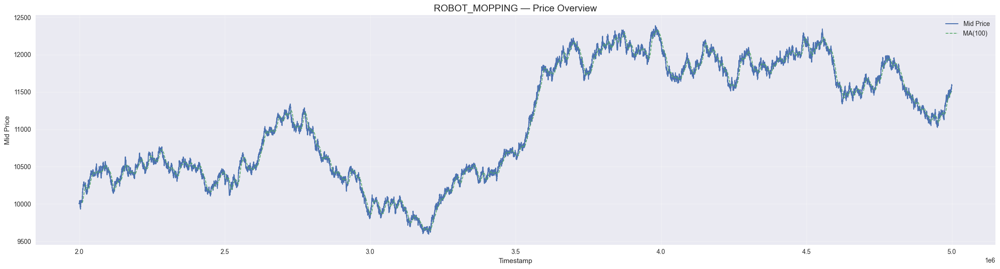

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10539.31,10535.5,10543.13
2,first half,10427.84,10424.05,10431.62
2,second half,10650.79,10646.94,10654.63
3,full day,11011.27,11007.31,11015.23
3,first half,10161.62,10157.94,10165.3
3,second half,11860.92,11856.68,11865.15
4,full day,11750.06,11745.87,11754.24
4,first half,11882.33,11878.11,11886.56
4,second half,11617.78,11613.64,11621.93



ROBOT_VACUUMING


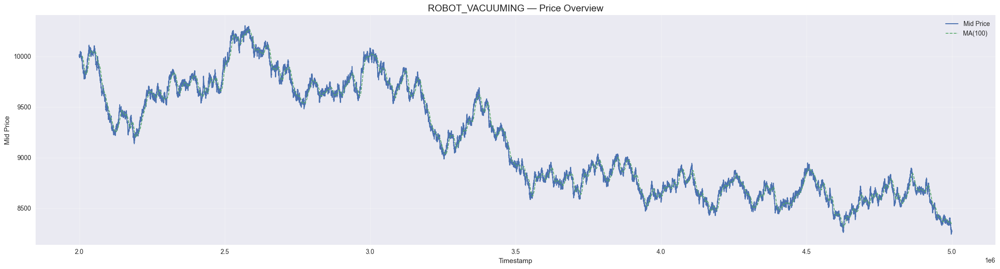

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9747.14,9743.57,9750.7
2,first half,9641.28,9637.74,9644.81
2,second half,9852.99,9849.4,9856.59
3,full day,9125.05,9121.69,9128.41
3,first half,9452.57,9449.11,9456.02
3,second half,8797.53,8794.26,8800.79
4,full day,8628.14,8624.94,8631.35
4,first half,8664.67,8661.45,8667.89
4,second half,8591.62,8588.43,8594.8



SLEEP_POD_COTTON


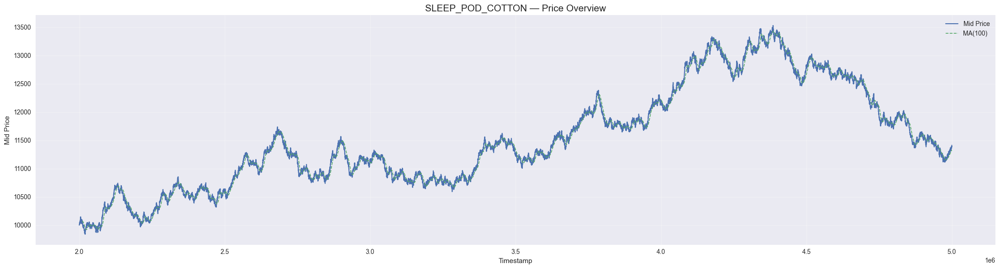

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10737.58,10732.86,10742.3
2,first half,10370.01,10365.43,10374.59
2,second half,11105.15,11100.29,11110.01
3,full day,11347.58,11342.63,11352.53
3,first half,11018.75,11013.94,11023.56
3,second half,11676.41,11671.32,11681.5
4,full day,12497.68,12492.27,12503.08
4,first half,12891.82,12886.26,12897.39
4,second half,12103.53,12098.29,12108.78



SLEEP_POD_LAMB_WOOL


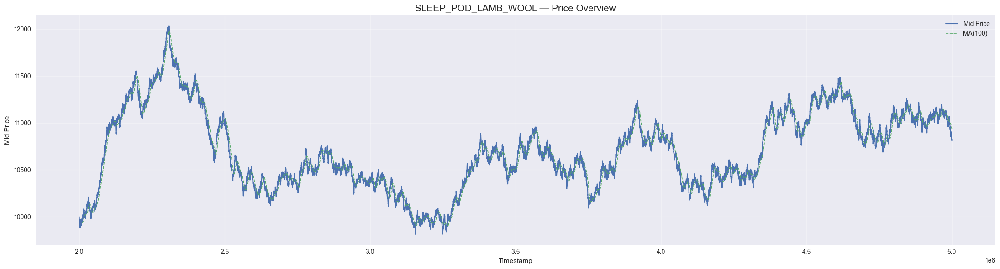

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10768.75,10764.01,10773.48
2,first half,11076.57,11071.71,11081.43
2,second half,10460.92,10456.31,10465.53
3,full day,10476.44,10471.83,10481.06
3,first half,10296.51,10291.98,10301.04
3,second half,10656.37,10651.68,10661.07
4,full day,10859.14,10854.38,10863.89
4,first half,10641.74,10637.07,10646.41
4,second half,11076.53,11071.69,11081.37



SLEEP_POD_NYLON


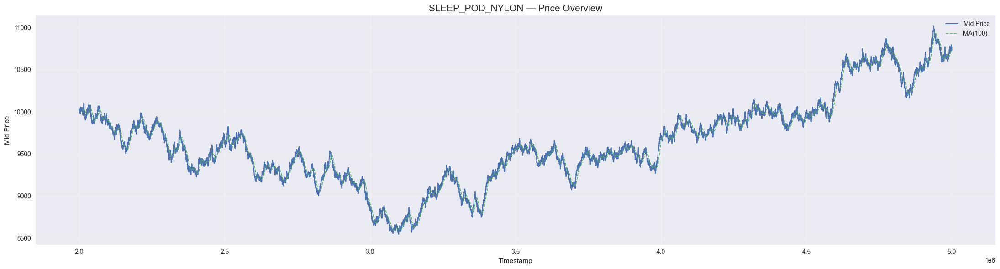

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9511.19,9506.95,9515.43
2,first half,9693.66,9689.35,9697.98
2,second half,9328.71,9324.55,9332.87
3,full day,9224.4,9220.28,9228.52
3,first half,8984.01,8979.99,8988.02
3,second half,9464.79,9460.57,9469.01
4,full day,10173.83,10169.34,10178.32
4,first half,9881.18,9876.81,9885.56
4,second half,10466.48,10461.87,10471.08



SLEEP_POD_POLYESTER


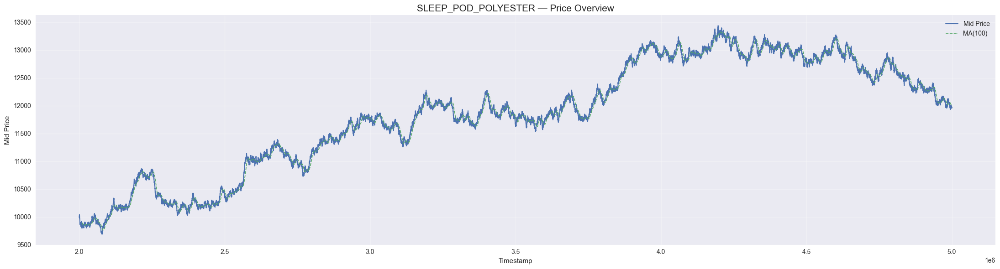

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10696.78,10692.08,10701.49
2,first half,10238.12,10233.59,10242.65
2,second half,11155.45,11150.57,11160.32
3,full day,12015.36,12010.14,12020.57
3,first half,11817.89,11812.76,11823.02
3,second half,12212.82,12207.51,12218.12
4,full day,12809.54,12804.02,12815.07
4,first half,13014.47,13008.87,13020.08
4,second half,12604.62,12599.17,12610.06



SLEEP_POD_SUEDE


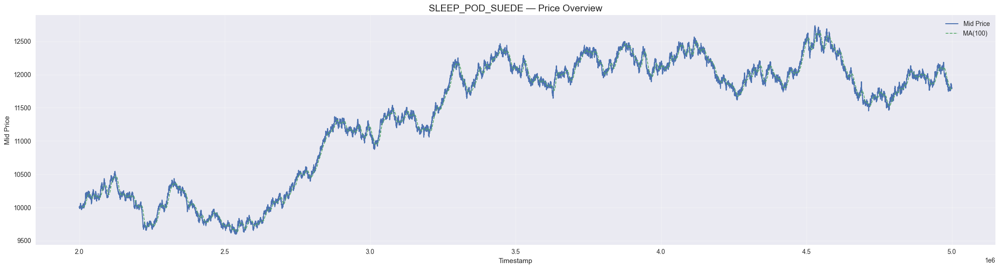

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10254.91,10250.37,10259.44
2,first half,10062.16,10057.7,10066.62
2,second half,10447.65,10443.05,10452.25
3,full day,11899.19,11894.02,11904.36
3,first half,11678.47,11673.39,11683.55
3,second half,12119.91,12114.64,12125.18
4,full day,12038.16,12032.95,12043.38
4,first half,12087.69,12082.45,12092.93
4,second half,11988.64,11983.44,11993.84



SNACKPACK_CHOCOLATE


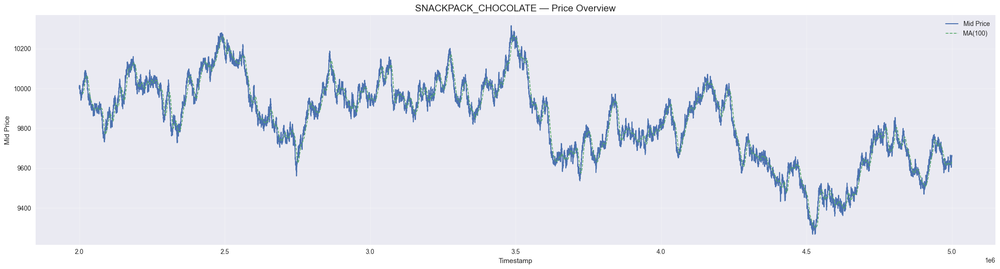

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9961.21,9952.87,9969.55
2,first half,9992.51,9984.14,10000.88
2,second half,9929.91,9921.6,9938.22
3,full day,9900.35,9892.07,9908.62
3,first half,10004.61,9996.27,10012.95
3,second half,9796.08,9787.88,9804.29
4,full day,9668.56,9660.47,9676.65
4,first half,9753.65,9745.5,9761.81
4,second half,9583.46,9575.44,9591.48



SNACKPACK_PISTACHIO


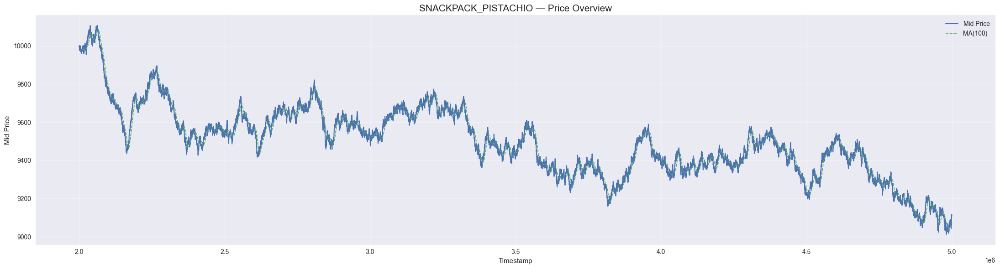

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9655.61,9647.51,9663.71
2,first half,9706.19,9698.04,9714.34
2,second half,9605.03,9596.98,9613.08
3,full day,9487.39,9479.44,9495.35
3,first half,9590.04,9582.02,9598.06
3,second half,9384.75,9376.86,9392.63
4,full day,9344.53,9336.69,9352.37
4,first half,9410.65,9402.76,9418.54
4,second half,9278.41,9270.63,9286.2



SNACKPACK_RASPBERRY


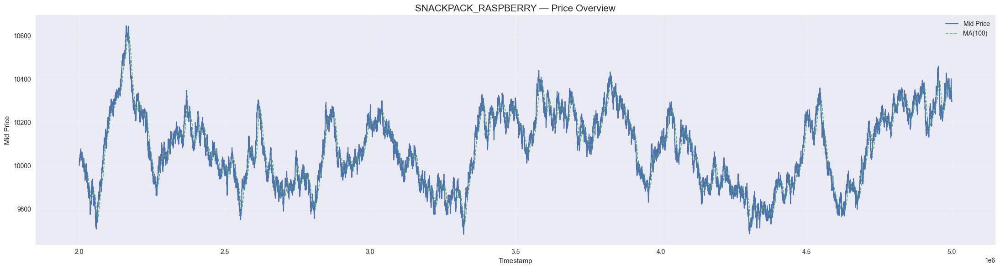

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10064.87,10056.45,10073.29
2,first half,10127.44,10118.96,10135.91
2,second half,10002.31,9993.95,10010.67
3,full day,10117.45,10109.0,10125.9
3,first half,10052.32,10043.94,10060.71
3,second half,10182.57,10174.05,10191.09
4,full day,10051.12,10042.72,10059.51
4,first half,9952.52,9944.21,9960.84
4,second half,10149.71,10141.24,10158.18



SNACKPACK_STRAWBERRY


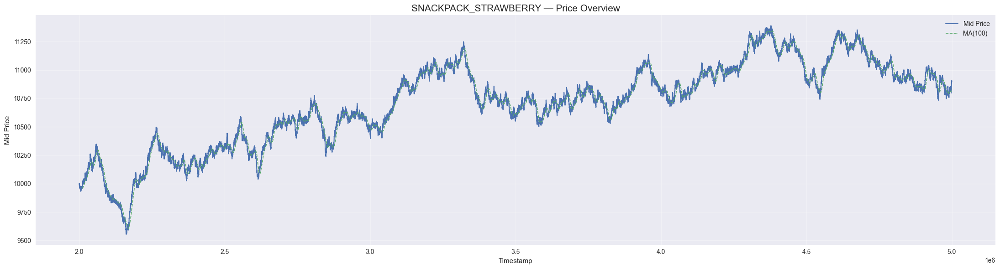

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10295.33,10286.73,10303.93
2,first half,10117.54,10109.07,10126.01
2,second half,10473.12,10464.39,10481.84
3,full day,10794.64,10785.66,10803.62
3,first half,10828.75,10819.76,10837.74
3,second half,10760.53,10751.57,10769.5
4,full day,11029.86,11020.69,11039.02
4,first half,11039.91,11030.74,11049.08
4,second half,11019.81,11010.65,11028.96



SNACKPACK_VANILLA


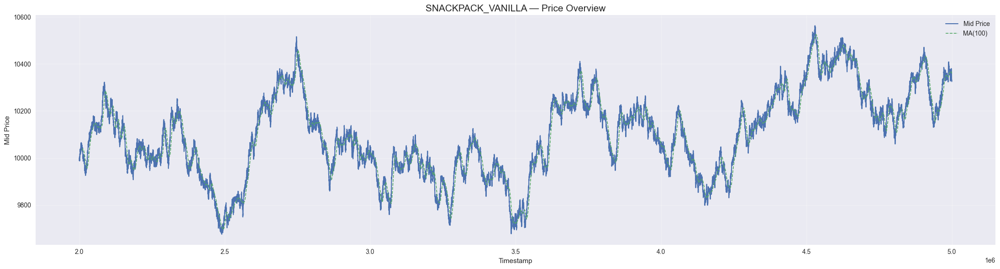

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10063.83,10055.42,10072.25
2,first half,10029.15,10020.75,10037.54
2,second half,10098.52,10090.09,10106.96
3,full day,10026.54,10018.16,10034.92
3,first half,9931.99,9923.7,9940.28
3,second half,10121.08,10112.62,10129.55
4,full day,10201.53,10193.03,10210.04
4,first half,10087.69,10079.27,10096.12
4,second half,10315.38,10306.78,10323.97



TRANSLATOR_ASTRO_BLACK


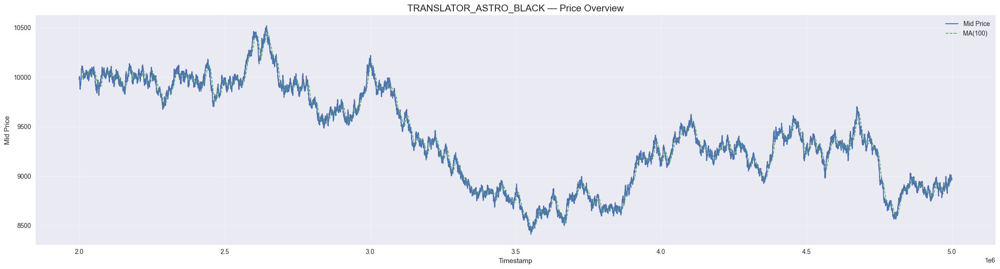

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9937.72,9933.31,9942.12
2,first half,9967.25,9962.82,9971.67
2,second half,9908.19,9903.8,9912.58
3,full day,9026.25,9022.22,9030.29
3,first half,9250.31,9246.19,9254.43
3,second half,8802.2,8798.24,8806.16
4,full day,9191.68,9187.58,9195.79
4,first half,9298.07,9293.93,9302.22
4,second half,9085.3,9081.23,9089.36



TRANSLATOR_ECLIPSE_CHARCOAL


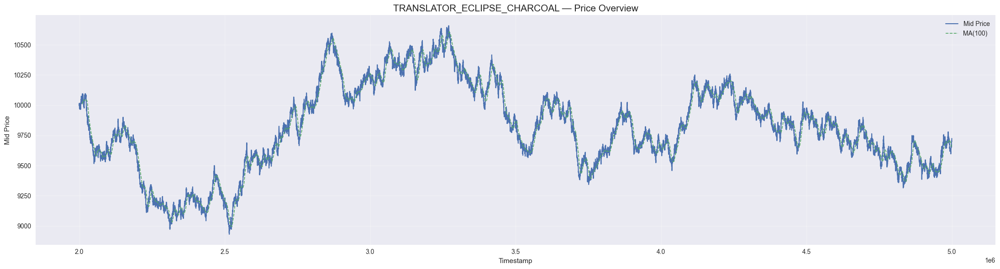

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9636.69,9632.4,9640.98
2,first half,9421.56,9417.35,9425.77
2,second half,9851.82,9847.46,9856.19
3,full day,10011.41,10006.99,10015.83
3,first half,10277.01,10272.5,10281.53
3,second half,9745.8,9741.48,9750.13
4,full day,9793.13,9788.79,9797.47
4,first half,9932.57,9928.18,9936.97
4,second half,9653.68,9649.39,9657.96



TRANSLATOR_GRAPHITE_MIST


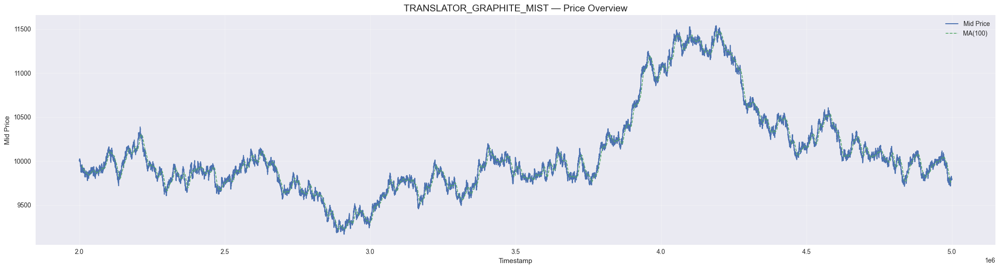

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9788.15,9783.81,9792.49
2,first half,9912.08,9907.68,9916.47
2,second half,9664.22,9659.93,9668.51
3,full day,9977.3,9972.89,9981.71
3,first half,9771.21,9766.88,9775.53
3,second half,10183.39,10178.89,10187.89
4,full day,10488.47,10483.86,10493.08
4,first half,10884.77,10880.0,10889.54
4,second half,10092.17,10087.71,10096.63



TRANSLATOR_SPACE_GRAY


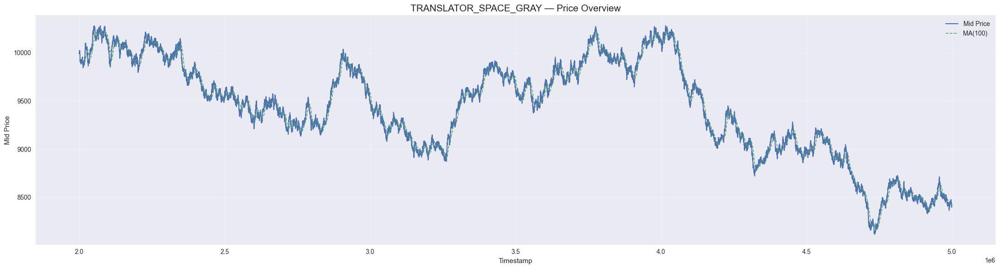

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9707.23,9702.91,9711.54
2,first half,9930.34,9925.93,9934.74
2,second half,9484.12,9479.9,9488.34
3,full day,9612.05,9607.78,9616.32
3,first half,9369.06,9364.89,9373.22
3,second half,9855.04,9850.66,9859.42
4,full day,8976.43,8972.41,8980.45
4,first half,9307.23,9303.08,9311.38
4,second half,8645.63,8641.74,8649.52



TRANSLATOR_VOID_BLUE


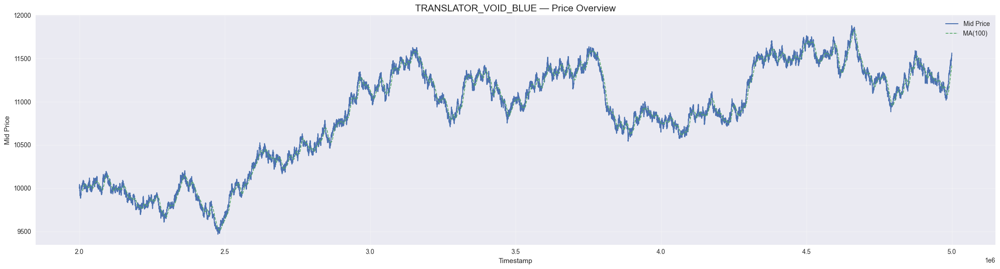

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10188.39,10183.89,10192.89
2,first half,9891.59,9887.2,9895.98
2,second half,10485.19,10480.57,10489.8
3,full day,11149.03,11144.15,11153.9
3,first half,11186.15,11181.26,11191.04
3,second half,11111.9,11107.03,11116.77
4,full day,11238.32,11233.42,11243.23
4,first half,11102.63,11097.78,11107.49
4,second half,11374.01,11369.05,11378.97



UV_VISOR_AMBER


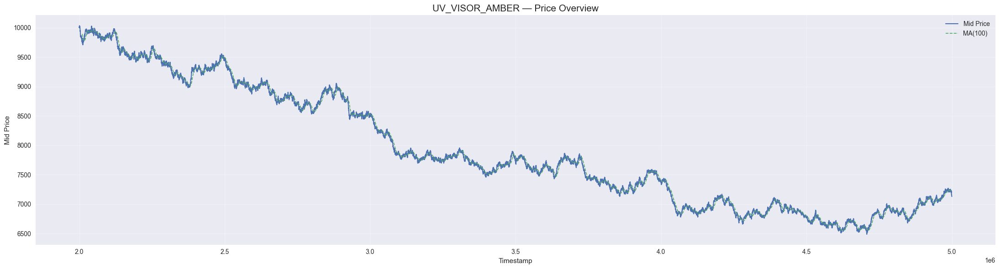

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9177.21,9171.29,9183.12
2,first half,9516.66,9510.53,9522.78
2,second half,8837.75,8832.05,8843.46
3,full day,7672.9,7667.88,7677.92
3,first half,7831.53,7826.43,7836.63
3,second half,7514.27,7509.33,7519.21
4,full day,6884.98,6880.43,6889.53
4,first half,6944.92,6940.34,6949.5
4,second half,6825.05,6820.53,6829.56



UV_VISOR_MAGENTA


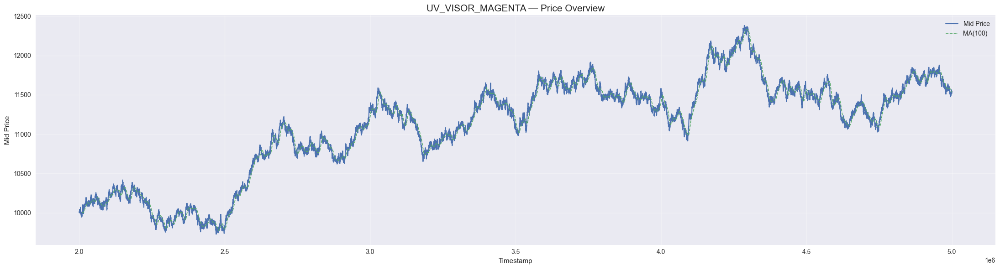

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10398.91,10392.27,10405.54
2,first half,10044.94,10038.51,10051.37
2,second half,10752.87,10746.04,10759.71
3,full day,11358.41,11351.22,11365.59
3,first half,11194.53,11187.46,11201.61
3,second half,11522.28,11514.98,11529.58
4,full day,11578.07,11570.75,11585.38
4,first half,11673.04,11665.67,11680.42
4,second half,11483.09,11475.83,11490.35



UV_VISOR_ORANGE


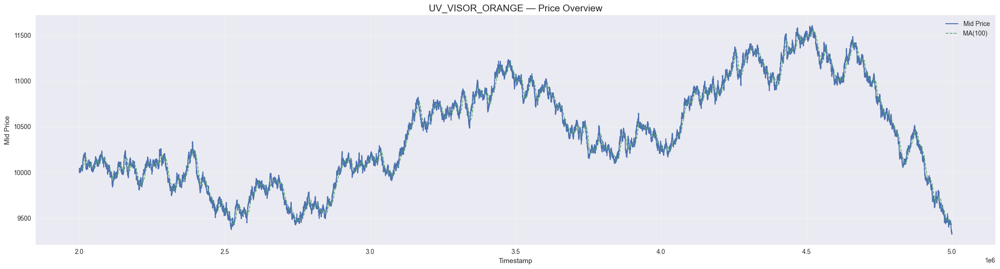

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,9876.9,9870.57,9883.23
2,first half,9986.99,9980.59,9993.39
2,second half,9766.82,9760.56,9773.07
3,full day,10574.23,10567.5,10580.96
3,first half,10616.96,10610.22,10623.7
3,second half,10531.5,10524.79,10538.21
4,full day,10828.39,10821.52,10835.26
4,first half,10992.12,10985.14,10999.09
4,second half,10664.66,10657.89,10671.44



UV_VISOR_RED


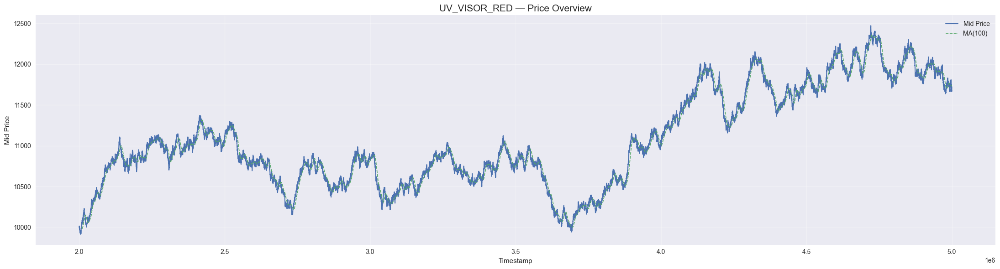

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10777.56,10770.7,10784.41
2,first half,10848.49,10841.58,10855.39
2,second half,10706.62,10699.81,10713.44
3,full day,10624.19,10617.43,10630.94
3,first half,10665.73,10658.96,10672.49
3,second half,10582.65,10575.9,10589.4
4,full day,11788.14,11780.69,11795.58
4,first half,11608.26,11600.92,11615.6
4,second half,11968.01,11960.46,11975.56



UV_VISOR_YELLOW


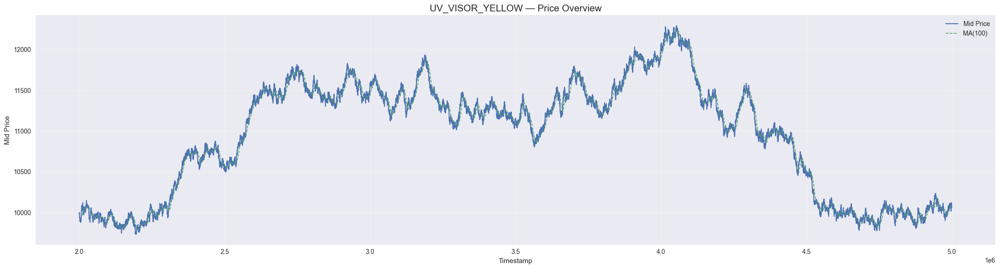

day,period,fair_mid,fair_best_bid,fair_best_ask
2,full day,10790.4,10783.53,10797.26
2,first half,10196.88,10190.36,10203.41
2,second half,11383.91,11376.7,11391.12
3,full day,11408.84,11401.62,11416.06
3,first half,11354.71,11347.54,11361.88
3,second half,11462.97,11455.7,11470.23
4,full day,10673.15,10666.37,10679.93
4,first half,11326.82,11319.65,11333.99
4,second half,10019.48,10013.08,10025.87



VELVETFRUIT_EXTRACT


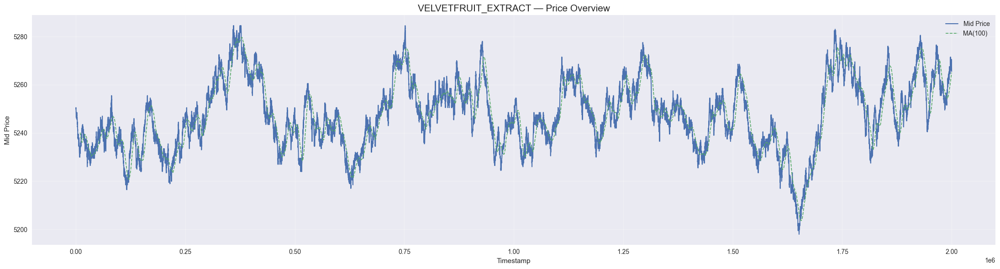

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,5246.51,5244.01,5249.01
0,first half,5245.23,5242.74,5247.73
0,second half,5247.79,5245.29,5250.28
1,full day,5248.39,5245.9,5250.88
1,first half,5248.36,5245.87,5250.84
1,second half,5248.43,5245.93,5250.93



VEV_4000


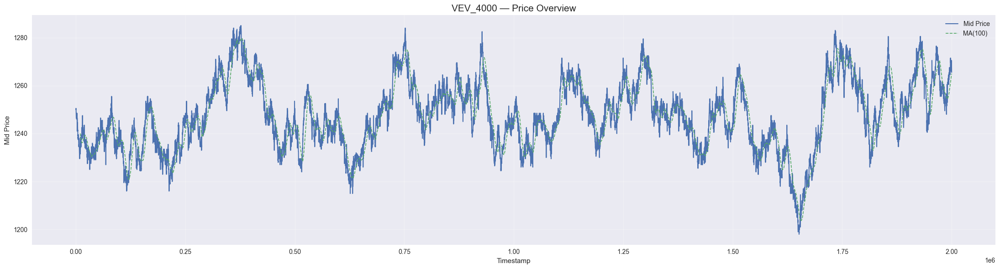

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,1246.52,1236.14,1256.91
0,first half,1245.24,1234.87,1255.62
0,second half,1247.8,1237.41,1258.2
1,full day,1248.41,1238.02,1258.8
1,first half,1248.38,1237.99,1258.78
1,second half,1248.43,1238.05,1258.82



VEV_4500


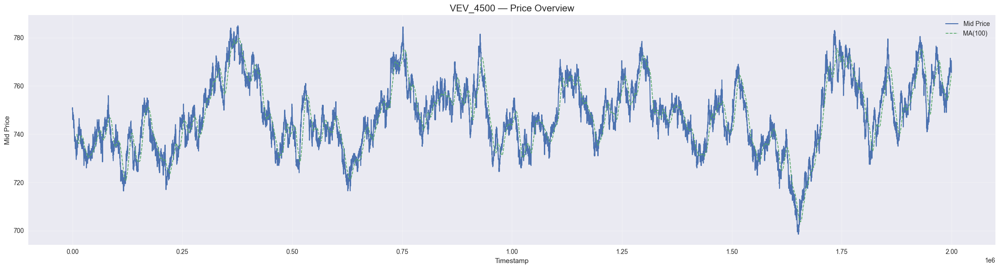

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,746.52,738.63,754.41
0,first half,745.24,737.36,753.12
0,second half,747.8,739.9,755.71
1,full day,748.41,740.5,756.31
1,first half,748.38,740.47,756.29
1,second half,748.43,740.53,756.34



VEV_5000


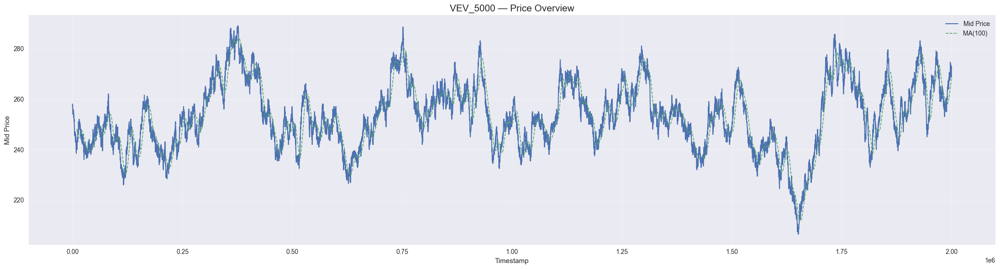

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,253.26,250.26,256.26
0,first half,252.38,249.38,255.37
0,second half,254.14,251.13,257.15
1,full day,253.26,250.26,256.27
1,first half,253.68,250.67,256.69
1,second half,252.85,249.85,255.85



VEV_5100


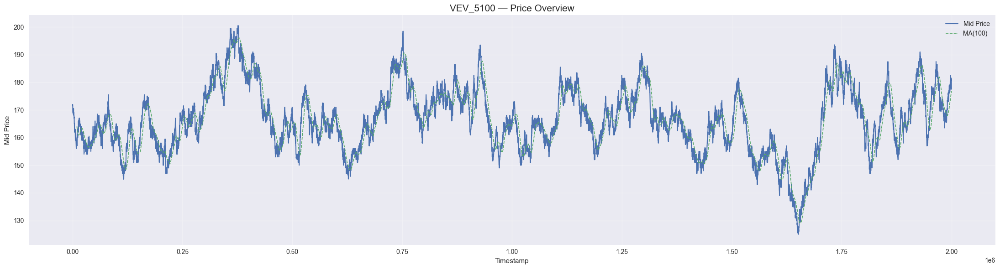

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,168.11,165.95,170.27
0,first half,167.66,165.51,169.82
0,second half,168.55,166.39,170.71
1,full day,164.98,162.85,167.11
1,first half,166.04,163.9,168.19
1,second half,163.92,161.81,166.04



VEV_5200


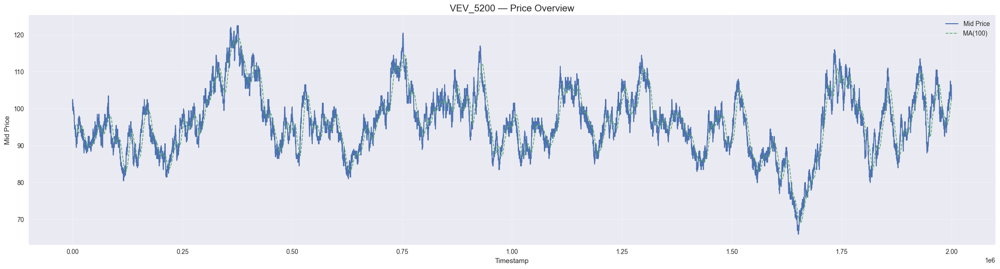

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,97.47,96.01,98.93
0,first half,97.25,95.79,98.71
0,second half,97.7,96.23,99.16
1,full day,95.13,93.69,96.57
1,first half,96.37,94.92,97.82
1,second half,93.89,92.46,95.32



VEV_5300


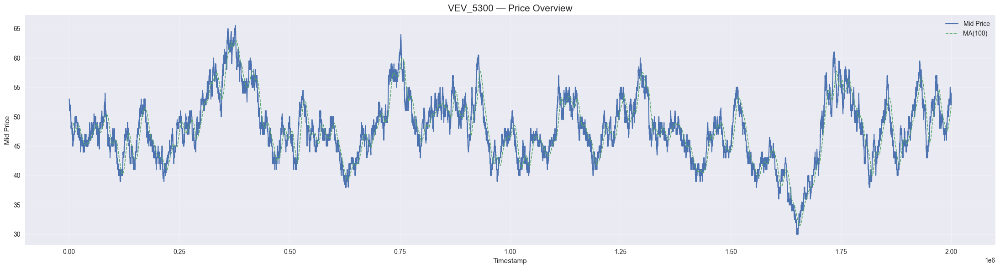

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,48.89,47.81,49.97
0,first half,49.18,48.09,50.26
0,second half,48.61,47.53,49.68
1,full day,46.91,45.85,47.96
1,first half,47.38,46.32,48.45
1,second half,46.44,45.39,47.48



VEV_5400


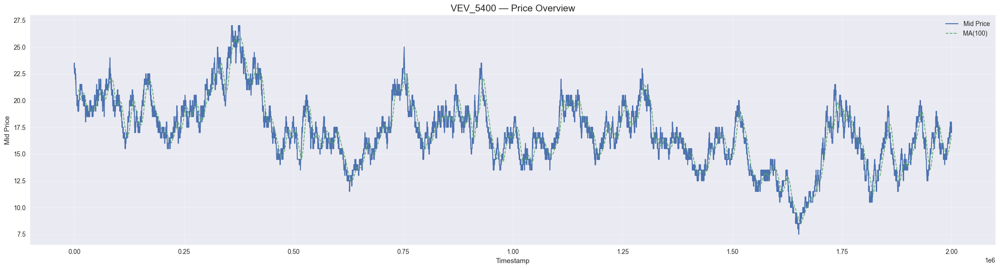

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,18.47,17.75,19.18
0,first half,19.79,19.06,20.52
0,second half,17.14,16.44,17.84
1,full day,15.65,14.96,16.35
1,first half,16.68,15.98,17.38
1,second half,14.63,13.94,15.31



VEV_5500


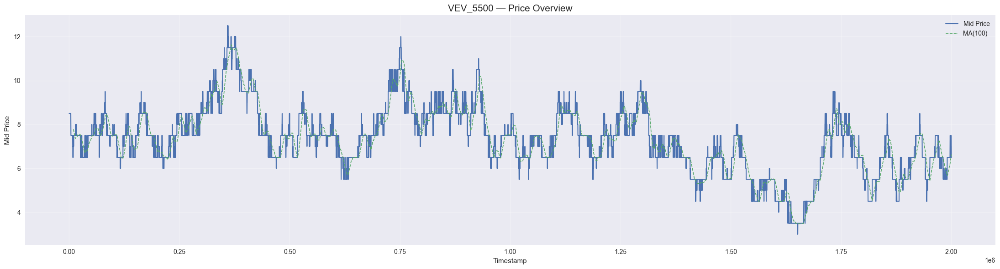

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,8.06,7.47,8.65
0,first half,8.09,7.5,8.68
0,second half,8.03,7.44,8.62
1,full day,6.57,5.99,7.15
1,first half,7.18,6.59,7.78
1,second half,5.96,5.39,6.52



VEV_6000


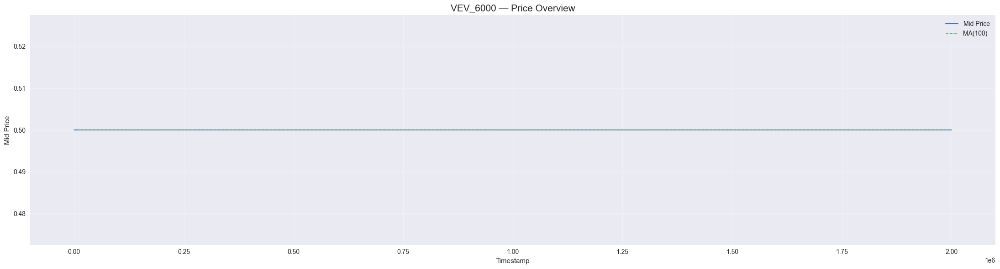

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,0.5,0.0,1.0
0,first half,0.5,0.0,1.0
0,second half,0.5,0.0,1.0
1,full day,0.5,0.0,1.0
1,first half,0.5,0.0,1.0
1,second half,0.5,0.0,1.0



VEV_6500


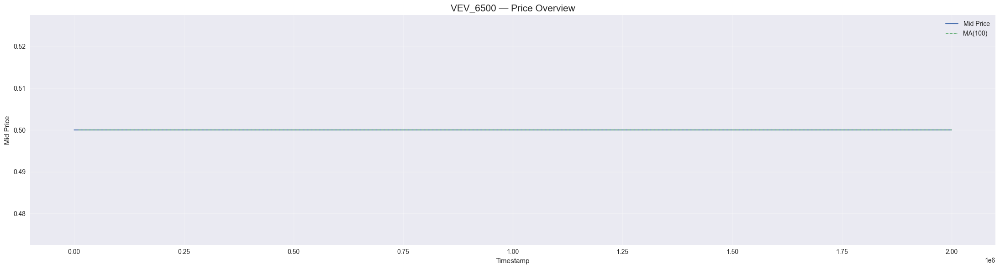

day,period,fair_mid,fair_best_bid,fair_best_ask
0,full day,0.5,0.0,1.0
0,first half,0.5,0.0,1.0
0,second half,0.5,0.0,1.0
1,full day,0.5,0.0,1.0
1,first half,0.5,0.0,1.0
1,second half,0.5,0.0,1.0


In [3]:
overview(df, window=100)


## 3 · Per-Product Price Evolution

Mid price + rolling MA + Z-score overlay.
Change `product` to any name returned by `get_products(df)`.


In [4]:
for product in get_products(df):
    plot_price_evolution(df, product, window=100, z_thresh=3.7, interactive=True)


## 4 · Bid-Ask Spread per Product

In [12]:
for product in get_products(df):
    plot_bid_ask_spread(df, product, window=100, interactive=True)


## 5 · Z-Score Velocity

First derivative of the Z-score — useful to detect momentum reversals.


In [15]:
for product in get_products(df):
    plot_zscore_velocity(df, product, window=100, smooth_window=3, interactive=True)


## 6 (formula for 6/7/8/9) · Spread Between Two Products

Define the spread as a linear combination of products.
`formula` is a dict of `{product_name: coefficient}`.

['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']

Examples:
- Simple pairwise spread : `{"TOMATOES": 1, "EMERALDS": -1}`
- Basket vs components   : `{"PICNIC_BASKET1": 1, "CROISSANTS": -6, "JAMS": -3, "DJEMBES": -1}`


In [22]:
# ── Edit the formula below ──────────────────────────────────────
products = get_products(df)
print("Available products:", products)
#Available products: ['ASH_COATED_OSMIUM', 'INTARIAN_PEPPER_ROOT']

# Example: change to match your actual products
# formula = {products[0]: 1, products[1]: -1}
formula = {"HYDROGEL_PACK": 1, "VELVETFRUIT_EXTRACT": -1}
# ────────────────────────────────────────────────────────────────

plot_spread(df, formula, window=50, interactive=True)


Available products: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


## 7 · Spread Z-Score (Interactive)

In [23]:
plot_spread_zscore(df, formula, window=50, z_thresh=2.0, interactive=True)


## 8 · Spread Statistics

Cumulative mean and std at each day boundary — useful to check whether
the spread is stable across days (good for mean-reversion trading).


In [24]:
stats = spread_stats(df, formula)


Spread formula  : HYDROGEL_PACK − VELVETFRUIT_EXTRACT
Overall  mean   : 4740.7088
Overall  std    : 34.1702

 timestamp  cumul_mean  cumul_std  n_obs
   1000000   4744.4487    21.9579  10001
   2000000   4744.0575    30.8917  20001
   3000000   4740.7088    34.1702  30000


## 9 · Normalised Spread (Z-Score Across the Whole Dataset)

Static Z-score using the overall mean & std — useful to calibrate
entry/exit thresholds for your bot.


In [25]:
m = compute_spread(df, formula)
overall_mean = m["spread"].mean()
overall_std  = m["spread"].std()
m["z_static"] = (m["spread"] - overall_mean) / overall_std

print(f"Overall mean : {overall_mean:.4f}")
print(f"Overall std  : {overall_std:.4f}")
print(f"Suggested entry z-threshold: ±{round(m['z_static'].abs().quantile(0.90), 2)}")

try:
    import plotly.graph_objects as go
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=m["timestamp"], y=m["z_static"],
                             name="Static Z-Score", line=dict(color="purple")))
    fig.add_hline(y= 2, line_dash="dash", line_color="green")
    fig.add_hline(y=-2, line_dash="dash", line_color="red")
    fig.add_hline(y= 0, line_dash="dot",  line_color="gray")
    fig.update_layout(title="Static Z-Score of Spread", template="plotly_white",
                      height=400, xaxis_title="Timestamp", yaxis_title="Z-Score")
    fig.show()
except ImportError:
    plt.figure(figsize=(22, 5))
    plt.plot(m["timestamp"], m["z_static"], color="purple", label="Static Z-Score")
    plt.axhline( 2, linestyle="--", color="green", alpha=0.6)
    plt.axhline(-2, linestyle="--", color="red",   alpha=0.6)
    plt.axhline( 0, linestyle=":",  color="gray",  alpha=0.4)
    plt.title("Static Z-Score of Spread")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


Overall mean : 4740.7088
Overall std  : 34.1702
Suggested entry z-threshold: ±1.66


## 10 · Cross-Edition Product Matching

Take **any product from this year** and find which products from P1/P2/P3
look most similar to it — ranked by Pearson r, R², and RMSE on their
normalised Z-score series.

This tells you: *"TOMATOES this year behaves like KELP from P2 (r=0.87)"*
— which lets you reuse last year's strategy.


Reference : HYDROGEL_PACK (current year, 30000 obs)
Rank  Edition  Product                         Pearson r       R²     RMSE       N
───────────────────────────────────────────────────────────────────────────
1     P3       KELP                               0.0734  -1.1308   1.4597  30,000
2     P3       RAINFOREST_RESIN                   0.0062  -0.8726   1.3684  30,000
3     P3       SQUID_INK                         -0.0078  -1.3849   1.5443  30,000
4     P3       MAGNIFICENT_MACARONS              -0.0464  -0.6019   1.2656  30,000
5     P3       VOLCANIC_ROCK                     -0.0556  -1.3337   1.5276  30,000


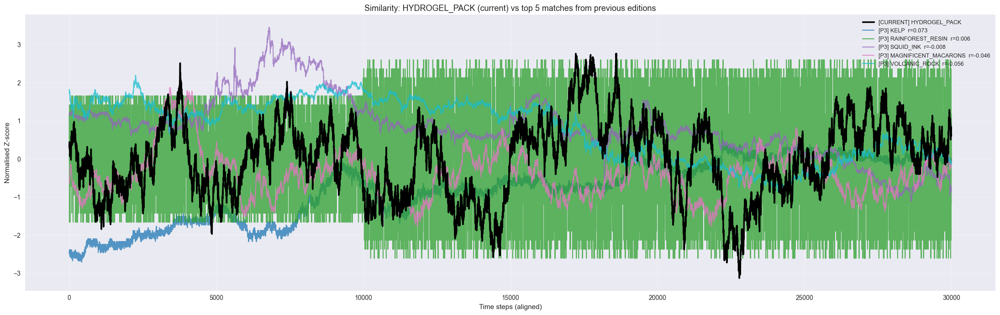

,edition,product,pearson_r,r2,rmse,n_obs
0,P3,KELP,0.0734,-1.1308,1.4597,30000
1,P3,RAINFOREST_RESIN,0.0062,-0.8726,1.3684,30000
2,P3,SQUID_INK,-0.0078,-1.3849,1.5443,30000
3,P3,MAGNIFICENT_MACARONS,-0.0464,-0.6019,1.2656,30000
4,P3,VOLCANIC_ROCK,-0.0556,-1.3337,1.5276,30000
5,P3,VOLCANIC_ROCK_VOUCHER_9500,-0.0622,-1.3188,1.5227,30000
6,P3,VOLCANIC_ROCK_VOUCHER_9750,-0.0640,-1.3442,1.5311,30000
7,P3,VOLCANIC_ROCK_VOUCHER_10000,-0.0805,-1.5557,1.5986,30000
8,P3,PICNIC_BASKET1,-0.0917,-1.9235,1.7098,30000
9,P3,PICNIC_BASKET2,-0.1243,-2.2132,1.7925,30000


In [27]:
# ── Load previous editions ──────────────────────────────────────
#df_p1 = load_prices("Prices", edition="P1")
#df_p2 = load_prices("Prices", edition="P2")
df_p3 = load_prices("Prices", edition="P3")

#edition_dfs = {"P1": df_p1, "P2": df_p2, "P3": df_p3}
edition_dfs = {"P3": df_p3}

# ── Choose the current-year product to match ────────────────────
PRODUCT_TO_MATCH = "HYDROGEL_PACK"   # ← change this

results = match_product_across_editions(
    current_product = PRODUCT_TO_MATCH,
    df_current      = df,
    edition_dfs     = edition_dfs,
    window          = 100,
    top_n           = 5,      # show the 5 best matches
    plot            = True,
)

# Full ranked table
results


## 11 · Trades (Order Book) Analysis

Basic order-flow analysis. Further functions will be added in the next version.


In [29]:
# Volume per product
vol = (df_trade.groupby("symbol")["quantity"].sum()
       .sort_values(ascending=False)
       .reset_index()
       .rename(columns={"symbol": "product", "quantity": "total_volume"}))
print(vol)


                product  total_volume
0   VELVETFRUIT_EXTRACT          8269
1         HYDROGEL_PACK          4078
2              VEV_6500          1002
3              VEV_6000          1002
4              VEV_4000           940
5              VEV_5500           937
6              VEV_5400           787
7              VEV_5300           420
8              VEV_5200            63
9              VEV_4500             1
10             VEV_5000             1
11             VEV_5100             1


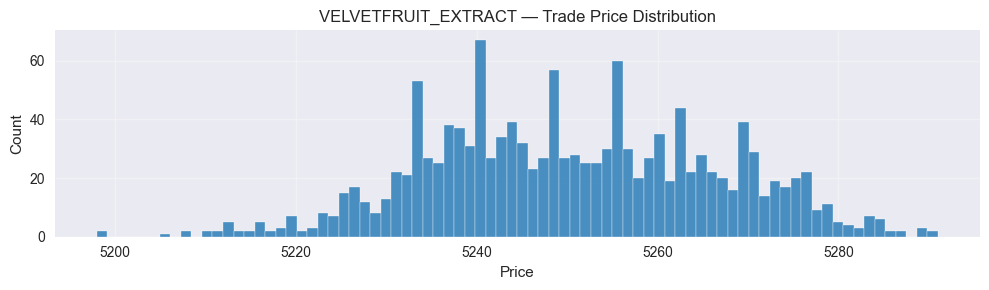

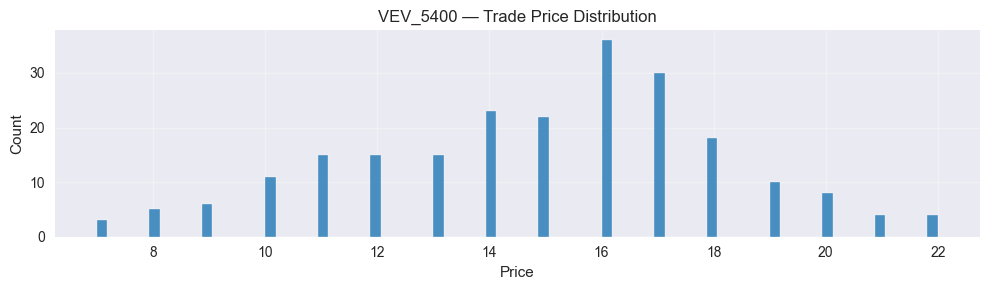

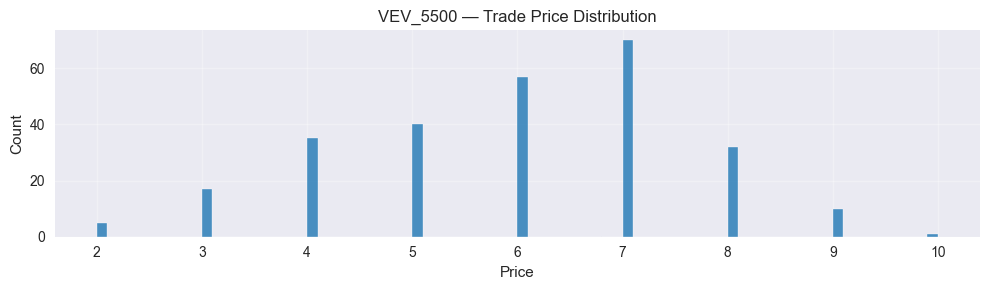

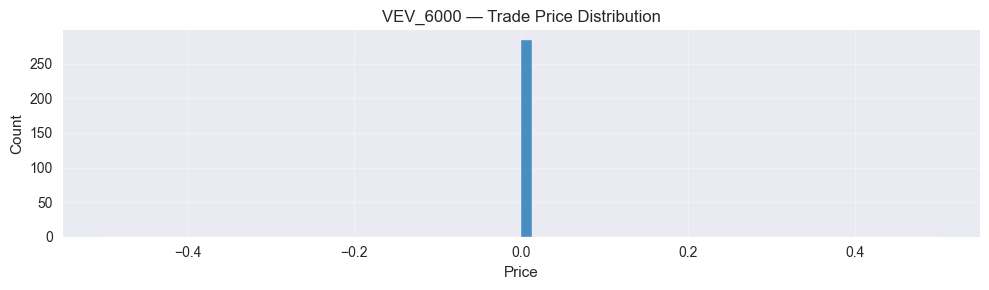

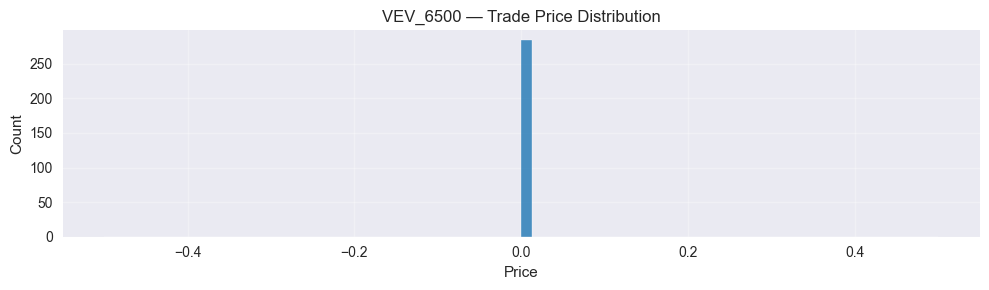

...

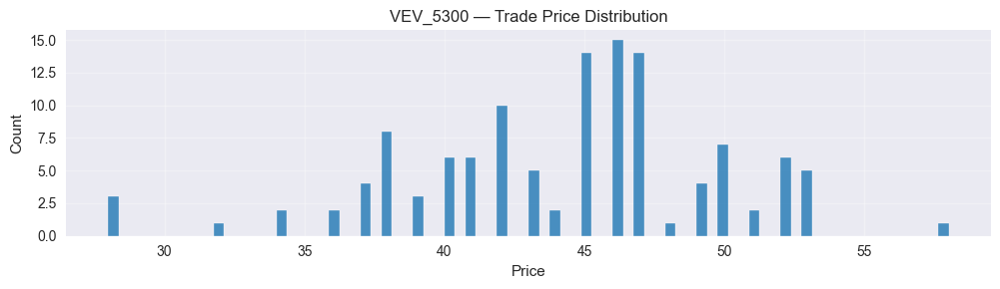

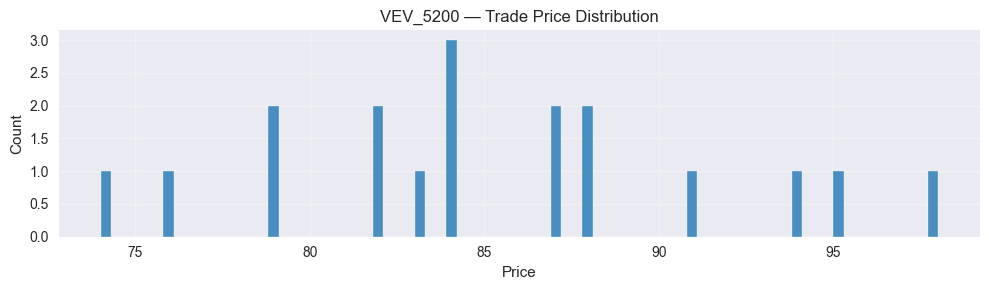

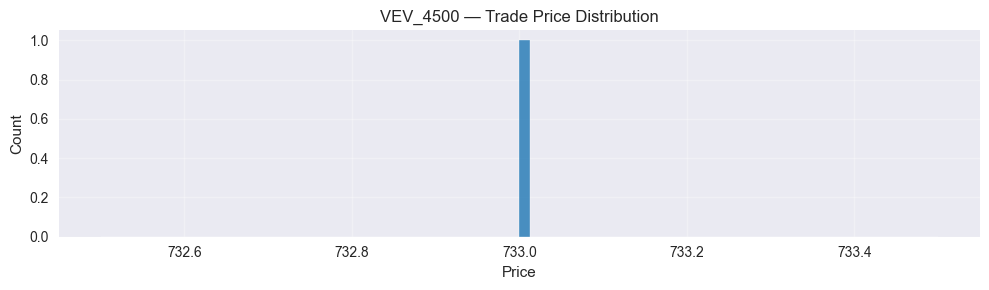

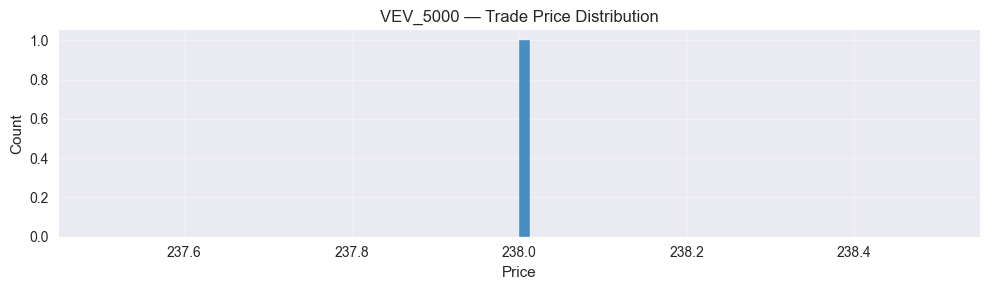

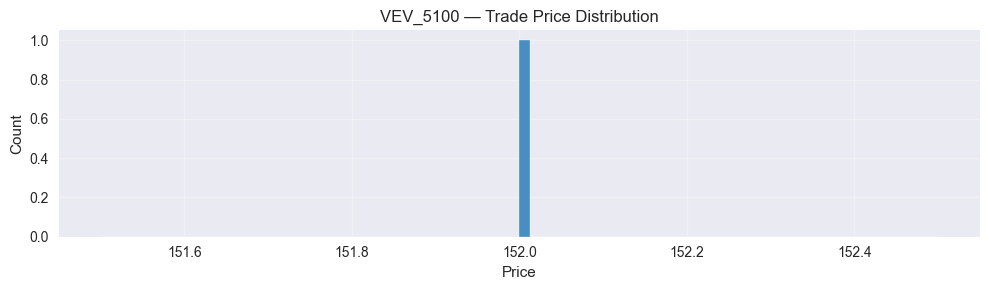

In [30]:
# Trade price distribution per product
for sym in df_trade["symbol"].dropna().unique():
    sub = df_trade[df_trade["symbol"] == sym]
    plt.figure(figsize=(10, 3))
    plt.hist(sub["price"].dropna(), bins=80, color="#1f77b4", edgecolor="white", alpha=0.8)
    plt.title(f"{sym} — Trade Price Distribution")
    plt.xlabel("Price")
    plt.ylabel("Count")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 12 · Order Book Analysis

Inspired by the Frankfurt Hedgehogs (2nd place globally, Prosperity 3).
Their core edge came from deeply reading market microstructure — not just price levels,
but *who* was trading, *how much*, and *when*.

In [31]:
from prosperity_analysis import (
    plot_orderbook_levels,
    compute_book_imbalance, plot_book_imbalance,
    plot_return_autocorrelation,
    trade_size_distribution,
    find_extrema_trades,
    compute_fill_edge, plot_fill_edge,
)

### 12a · Order Book Levels Over Time
All three bid/ask levels plotted simultaneously. Blue = bids, Red = asks.
Look for "wall" levels — stable, thick lines that barely move. Those are the
market maker anchors and your best fair-value estimate.

In [32]:
for product in get_products(df):
    plot_orderbook_levels(df, product, interactive=True)

### 12b · Book Imbalance
(total bid volume − total ask volume) / total volume, rolling MA overlay.
Sustained imbalance in one direction precedes price moves. Key signal for timing
entries on mean-reverting products.

In [33]:
for product in get_products(df):
    plot_book_imbalance(df, product, window=50, interactive=True)

### 12c · Return Autocorrelation
Tests whether mid-price returns are mean-reverting (negative lag-1 ACF),
trending (positive), or random (within the grey band).
This is exactly how the winners confirmed Squid Ink and Volcanic Rock
were mean-reverting before committing to that strategy.

In [34]:
for product in get_products(df):
    plot_return_autocorrelation(df, product, max_lag=20, n_random=100, interactive=True)

### 12d · Trade Size Distribution
Histogram of trade sizes per product.
A spike at a specific round number (e.g. always 15) = signature of a systematic bot.
The winners identified "Olivia" this way in Prosperity 3 — she always traded 15 lots
at the daily high/low.

In [35]:
for sym in get_products(df_trade, col="symbol"):
    trade_size_distribution(df_trade, sym, interactive=True)


Top 10 most common trade sizes for HYDROGEL_PACK:
 size  count
    5    212
    6    205
    4    202
    3    198
    2    193



Top 10 most common trade sizes for VELVETFRUIT_EXTRACT:
 size  count
    8    233
    7    224
    5    223
    6    212
    3    190
    4    189
   10     29
    9     23
   13     13
   12     11



Top 10 most common trade sizes for VEV_4000:
 size  count
    2    160
    3    158
    1    146



Top 10 most common trade sizes for VEV_4500:
 size  count
    1      1



Top 10 most common trade sizes for VEV_5000:
 size  count
    1      1



Top 10 most common trade sizes for VEV_5100:
 size  count
    1      1


... (2 outputs left out)


Top 10 most common trade sizes for VEV_5400:
 size  count
    2     62
    4     60
    5     57
    3     46



Top 10 most common trade sizes for VEV_5500:
 size  count
    2     73
    4     73
    5     68
    3     53



Top 10 most common trade sizes for VEV_6000:
 size  count
    4     78
    2     76
    5     74
    3     56



Top 10 most common trade sizes for VEV_6500:
 size  count
    4     78
    2     76
    5     74
    3     56


### 12e · Informed Trader Detection — Extrema Trades
Flags trades that occurred near the daily high or low.
If a specific quantity dominates these flags, that's your "Olivia" for this year.
Change `qty_filter` to any suspicious size found in 12d.

In [36]:
for sym in get_products(df_trade, col="symbol"):
    # First pass: no size filter — see all extrema trades
    flagged = find_extrema_trades(df, df_trade, sym, qty_filter=None, tolerance=0.002)
    display(flagged.head(10))

Trades near daily extrema for HYDROGEL_PACK:
  Near daily LOW  : 6
  Near daily HIGH : 3

Buyers  at daily LOW  : {}
Sellers at daily HIGH : {}


,timestamp,buyer,seller,symbol,currency,price,quantity,day,day_low,day_high,flag
28,109500,NaN,NaN,HYDROGEL_PACK,XIRECS,9926.0,2,0,9928.0,10071.0,low
499,1441300,NaN,NaN,HYDROGEL_PACK,XIRECS,9902.0,2,1,9908.5,10079.0,low
500,1443600,NaN,NaN,HYDROGEL_PACK,XIRECS,9908.0,2,1,9908.5,10079.0,low
606,1772000,NaN,NaN,HYDROGEL_PACK,XIRECS,10082.0,6,1,9908.5,10079.0,high
640,1860100,NaN,NaN,HYDROGEL_PACK,XIRECS,10086.0,2,1,9908.5,10079.0,high
774,2278800,NaN,NaN,HYDROGEL_PACK,XIRECS,9890.0,2,2,9891.0,10051.0,low
775,2279900,NaN,NaN,HYDROGEL_PACK,XIRECS,9890.0,6,2,9891.0,10051.0,low
776,2282200,NaN,NaN,HYDROGEL_PACK,XIRECS,9891.0,4,2,9891.0,10051.0,low
939,2771300,NaN,NaN,HYDROGEL_PACK,XIRECS,10051.0,4,2,9891.0,10051.0,high


Trades near daily extrema for VELVETFRUIT_EXTRACT:
  Near daily LOW  : 2
  Near daily HIGH : 3

Buyers  at daily LOW  : {}
Sellers at daily HIGH : {}


,timestamp,buyer,seller,symbol,currency,price,quantity,day,day_low,day_high,flag
145,374900,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5287.0,3,0,5216.5,5284.5,high
146,376500,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5287.0,3,0,5216.5,5284.5,high
147,376700,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5286.0,8,0,5216.5,5284.5,high
751,1650300,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5198.0,6,1,5198.0,5283.0,low
752,1652100,NaN,NaN,VELVETFRUIT_EXTRACT,XIRECS,5198.0,6,1,5198.0,5283.0,low


Trades near daily extrema for VEV_4000:
  Near daily LOW  : 5
  Near daily HIGH : 4

Buyers  at daily LOW  : {}
Sellers at daily HIGH : {}


,timestamp,buyer,seller,symbol,currency,price,quantity,day,day_low,day_high,flag
17,116000,NaN,NaN,VEV_4000,XIRECS,1206.0,1,0,1215.0,1285.0,low
31,213000,NaN,NaN,VEV_4000,XIRECS,1209.0,1,0,1215.0,1285.0,low
64,374900,NaN,NaN,VEV_4000,XIRECS,1295.0,1,0,1215.0,1285.0,high
105,622100,NaN,NaN,VEV_4000,XIRECS,1213.0,2,0,1215.0,1285.0,low
125,748000,NaN,NaN,VEV_4000,XIRECS,1286.0,1,0,1215.0,1285.0,high
287,1647200,NaN,NaN,VEV_4000,XIRECS,1196.0,3,1,1198.0,1283.0,low
327,1929100,NaN,NaN,VEV_4000,XIRECS,1289.0,2,1,1198.0,1283.0,high
410,2587500,NaN,NaN,VEV_4000,XIRECS,1202.0,1,2,1207.0,1300.0,low
463,2998800,NaN,NaN,VEV_4000,XIRECS,1307.0,3,2,1207.0,1300.0,high


... (14 outputs left out)

Trades near daily extrema for VEV_6000:
  Near daily LOW  : 0
  Near daily HIGH : 0

Buyers  at daily LOW  : {}
Sellers at daily HIGH : {}


,timestamp,buyer,seller,symbol,currency,price,quantity,day,day_low,day_high,flag


Trades near daily extrema for VEV_6500:
  Near daily LOW  : 0
  Near daily HIGH : 0

Buyers  at daily LOW  : {}
Sellers at daily HIGH : {}


,timestamp,buyer,seller,symbol,currency,price,quantity,day,day_low,day_high,flag


### 12f · Fill Edge Analysis
How far did each trade cross the mid-price?
Large absolute edge = aggressive taker, possibly informed.
Useful to: (a) understand who is paying up and why, (b) calibrate your own
taker logic to avoid giving too much edge away.

In [ ]:
for sym in get_products(df_trade, col="symbol"):
    plot_fill_edge(df, df_trade, sym, interactive=True)

Fill edge summary for ASH_COATED_OSMIUM:
  Mean |edge| : 8.9943
  Max  |edge| : 29.0000
  Median edge : 1.0000


Fill edge summary for INTARIAN_PEPPER_ROOT:
  Mean |edge| : 1000.0371
  Max  |edge| : 1013.0000
  Median edge : 1000.5000


## 13 · Bot Tracker — 10-Lot Osmium

Tracks the systematic bot that always trades in exactly **10-lot orders** on `ASH_COATED_OSMIUM`.
Based on the Frankfurt Hedgehogs methodology: find signature trade sizes, overlay them on price.

**Direction logic:** compare trade price vs concurrent book.
- Trade at ask₁ → bot is **buying** (lifted the ask) → 🔼 green arrow UP
- Trade at bid₁ → bot is **selling** (hit the bid) → 🔽 red arrow DOWN

**Data required:** `trades_round_1_day_X.csv` files in your `Prices/` folder.
These arrive each round alongside the price files.

In [40]:
import pandas as pd
import numpy as np

BOT_QTY   = 1             # the bot's signature lot size
PRODUCT   = "VEV_4000"            # same as your loader

# ── 1. Load all price files for this product ─────────────────────────────────
df_prices = load_prices("DATA_DIR")   # already loaded if you ran section 1
osm_prices = df_prices[df_prices["product"] == PRODUCT].copy()
for c in ["bid_price_1","ask_price_1","bid_price_2","ask_price_2"]:
    osm_prices[c] = pd.to_numeric(osm_prices[c], errors="coerce")
osm_prices = osm_prices.sort_values("timestamp").reset_index(drop=True)
osm_prices["wall_mid"] = (
    osm_prices["bid_price_2"].fillna(osm_prices["bid_price_1"]) +
    osm_prices["ask_price_2"].fillna(osm_prices["ask_price_1"])
) / 2

# ── 2. Load all trade files ───────────────────────────────────────────────────
df_trades = load_trades("DATA_DIR")

if df_trades.empty:
    print("⚠  No trade files found yet — add trades_round_1_day_X.csv to Prices/")
else:
    # ── 3. Filter: only this product, only 10-lot orders ─────────────────────
    bot_trades = df_trades[
        (df_trades["symbol"] == PRODUCT) &
        (df_trades["quantity"].abs() == BOT_QTY)
    ].copy()
    bot_trades["timestamp"] = pd.to_numeric(bot_trades["timestamp"], errors="coerce")
    bot_trades["price"]     = pd.to_numeric(bot_trades["price"],     errors="coerce")
    bot_trades["quantity"]  = pd.to_numeric(bot_trades["quantity"],  errors="coerce").abs()
    bot_trades = bot_trades.sort_values("timestamp").reset_index(drop=True)

    # ── 4. Infer direction by comparing trade price to concurrent book ────────
    # Nearest-timestamp merge: snap each trade to the closest book snapshot
    book_snap = osm_prices[["timestamp","bid_price_1","ask_price_1","wall_mid"]].dropna(
        subset=["bid_price_1","ask_price_1"]
    )
    bot_trades = pd.merge_asof(
        bot_trades,
        book_snap,
        on="timestamp",
        direction="nearest",
        tolerance=500,         # within 500 ticks = same book snapshot
    )

    def infer_direction(row):
        if pd.isna(row["ask_price_1"]) or pd.isna(row["bid_price_1"]):
            return "UNKNOWN"
        if row["price"] >= row["ask_price_1"] - 0.5:
            return "BUY"         # traded at or above ask → lifted ask → bot buying
        elif row["price"] <= row["bid_price_1"] + 0.5:
            return "SELL"        # traded at or below bid → hit bid → bot selling
        else:
            return "MID"         # inside spread — rare, mark separately

    bot_trades["direction"] = bot_trades.apply(infer_direction, axis=1)

    print(f"Total 10-lot bot trades found : {len(bot_trades)}")
    print(f"  BUY  (bot lifted ask) : {(bot_trades['direction']=='BUY').sum()}")
    print(f"  SELL (bot hit bid)    : {(bot_trades['direction']=='SELL').sum()}")
    print(f"  MID  (inside spread)  : {(bot_trades['direction']=='MID').sum()}")
    print(f"  UNKNOWN (no book snap): {(bot_trades['direction']=='UNKNOWN').sum()}")
    print()

    # ── 5. Daily extrema check: is the bot trading near highs/lows? ───────────
    bot_trades["day_idx"] = bot_trades["timestamp"] // 1_000_000
    daily = osm_prices.copy()
    daily["day_idx"] = daily["timestamp"] // 1_000_000
    daily_ranges = daily.groupby("day_idx")["wall_mid"].agg(d_lo="min", d_hi="max").reset_index()
    bot_trades = bot_trades.merge(daily_ranges, on="day_idx", how="left")
    bot_trades["pct_of_range"] = (
        (bot_trades["wall_mid"] - bot_trades["d_lo"]) /
        (bot_trades["d_hi"]    - bot_trades["d_lo"] + 1e-9)
    )

    buy_pct  = bot_trades[bot_trades["direction"]=="BUY"]["pct_of_range"].mean()
    sell_pct = bot_trades[bot_trades["direction"]=="SELL"]["pct_of_range"].mean()
    print(f"Bot BUY  mean position in daily range  : {buy_pct:.3f}  (0=low, 1=high)")
    print(f"Bot SELL mean position in daily range  : {sell_pct:.3f}  (0=low, 1=high)")
    print(f"  → If BUY ≈ 0.1–0.3 and SELL ≈ 0.7–0.9  →  bot trades at extrema ✓")

Total 10-lot bot trades found : 146
  BUY  (bot lifted ask) : 69
  SELL (bot hit bid)    : 77
  MID  (inside spread)  : 0
  UNKNOWN (no book snap): 0

Bot BUY  mean position in daily range  : 0.525  (0=low, 1=high)
Bot SELL mean position in daily range  : 0.532  (0=low, 1=high)
  → If BUY ≈ 0.1–0.3 and SELL ≈ 0.7–0.9  →  bot trades at extrema ✓


In [41]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

if df_trades.empty:
    print("⚠  No trade files — run after adding trades_round_1_day_X.csv")
else:
    buys  = bot_trades[bot_trades["direction"] == "BUY"]
    sells = bot_trades[bot_trades["direction"] == "SELL"]
    mids  = bot_trades[bot_trades["direction"] == "MID"]

    # ── Arrow offset: place arrow tip AT the trade price, tail above/below ──
    ARROW_LEN = 3   # ticks — adjust if arrows feel too big or too small

    fig = go.Figure()

    # ── 1. Mid-price line ────────────────────────────────────────────────────
    fig.add_trace(go.Scatter(
        x=osm_prices["timestamp"],
        y=osm_prices["wall_mid"],
        mode="lines",
        name="Wall Mid",
        line=dict(color="#4c78a8", width=1.5),
        opacity=0.85,
    ))

    # ── 2. BUY arrows (green, pointing UP, tip at trade price) ───────────────
    if len(buys) > 0:
        for _, row in buys.iterrows():
            fig.add_annotation(
                x=row["timestamp"],
                y=row["price"],
                ax=row["timestamp"],
                ay=row["price"] - ARROW_LEN,      # tail is BELOW the tip
                xref="x", yref="y",
                axref="x", ayref="y",
                showarrow=True,
                arrowhead=2,
                arrowsize=1.4,
                arrowwidth=2,
                arrowcolor="#27ae60",              # green
                text="",
            )
        # Invisible scatter for the legend entry
        fig.add_trace(go.Scatter(
            x=buys["timestamp"],
            y=buys["price"],
            mode="markers",
            name=f"Bot BUY ×{BOT_QTY}  (n={len(buys)})",
            marker=dict(symbol="triangle-up", color="#27ae60", size=10),
            hovertemplate=(
                "<b>BOT BUY</b><br>"
                "Timestamp: %{x}<br>"
                "Price: %{y}<br>"
                "Pct of day range: %{customdata:.2f}"
                "<extra></extra>"
            ),
            customdata=buys["pct_of_range"].values,
        ))

    # ── 3. SELL arrows (red, pointing DOWN, tip at trade price) ──────────────
    if len(sells) > 0:
        for _, row in sells.iterrows():
            fig.add_annotation(
                x=row["timestamp"],
                y=row["price"],
                ax=row["timestamp"],
                ay=row["price"] + ARROW_LEN,      # tail is ABOVE the tip
                xref="x", yref="y",
                axref="x", ayref="y",
                showarrow=True,
                arrowhead=2,
                arrowsize=1.4,
                arrowwidth=2,
                arrowcolor="#e74c3c",              # red
                text="",
            )
        fig.add_trace(go.Scatter(
            x=sells["timestamp"],
            y=sells["price"],
            mode="markers",
            name=f"Bot SELL ×{BOT_QTY}  (n={len(sells)})",
            marker=dict(symbol="triangle-down", color="#e74c3c", size=10),
            hovertemplate=(
                "<b>BOT SELL</b><br>"
                "Timestamp: %{x}<br>"
                "Price: %{y}<br>"
                "Pct of day range: %{customdata:.2f}"
                "<extra></extra>"
            ),
            customdata=sells["pct_of_range"].values,
        ))

    # ── 4. MID trades (grey dots, rare) ──────────────────────────────────────
    if len(mids) > 0:
        fig.add_trace(go.Scatter(
            x=mids["timestamp"],
            y=mids["price"],
            mode="markers",
            name=f"Bot MID ×{BOT_QTY}  (n={len(mids)})",
            marker=dict(symbol="circle", color="grey", size=7, opacity=0.6),
        ))

    # ── 5. Day boundary lines ────────────────────────────────────────────────
    for day_ts in range(1_000_000, int(osm_prices["timestamp"].max()), 1_000_000):
        fig.add_vline(
            x=day_ts, line_dash="dot",
            line_color="rgba(150,150,150,0.4)", line_width=1,
        )

    # ── Layout ────────────────────────────────────────────────────────────────
    fig.update_layout(
        title=dict(
            text=f"<b>{PRODUCT}</b> — 10-Lot Bot Activity",
            font=dict(size=18),
        ),
        xaxis_title="Timestamp",
        yaxis_title="Price",
        template="plotly_white",
        height=600,
        legend=dict(
            orientation="h",
            yanchor="bottom", y=1.02,
            xanchor="left",   x=0,
            font=dict(size=12),
        ),
        hovermode="x unified",
        margin=dict(t=80, b=50),
    )
    fig.show()

In [43]:
if not df_trades.empty and len(bot_trades) > 0:
    summary = (
        bot_trades.groupby(["day_idx", "direction"])
        .agg(
            count=("price", "count"),
            mean_price=("price", "mean"),
            mean_pct_range=("pct_of_range", "mean"),
        )
        .round(3)
        .reset_index()
    )
    print("=== Bot activity summary by day ===")
    print(summary.to_string(index=False))
    print()

    # Quick verdict
    b = bot_trades[bot_trades["direction"]=="BUY"]["pct_of_range"].mean()
    s = bot_trades[bot_trades["direction"]=="SELL"]["pct_of_range"].mean()
    if b < 0.35 and s > 0.65:
        print(f"✅  Pattern CONFIRMED — bot buys near LOWS ({b:.2f}) and sells near HIGHS ({s:.2f})")
        print(f"   → Follow this bot: copy its direction after it fires.")
    elif b > 0.65 and s < 0.35:
        print(f"✅  Pattern CONFIRMED (REVERSED) — bot buys near HIGHS and sells near LOWS")
        print(f"   → This bot is an informed short-term momentum trader.")
    else:
        print(f"⚠  No clear extrema pattern (buy_pct={b:.2f}, sell_pct={s:.2f})")
        print(f"   → Bot trades randomly in the range, or sample is too small.")

=== Bot activity summary by day ===
 day_idx direction  count  mean_price  mean_pct_range
       0       BUY     25    1261.200           0.499
       0      SELL     26    1238.154           0.468
       1       BUY     23    1258.304           0.587
       1      SELL     32    1237.125           0.582
       2       BUY     21    1263.381           0.489
       2      SELL     19    1246.421           0.533

⚠  No clear extrema pattern (buy_pct=0.53, sell_pct=0.53)
   → Bot trades randomly in the range, or sample is too small.


## 14 · Bot Signal Conditioning

The 10-lot bot is a *correct* mean-reversion trader — it buys after falls, sells after rises.
The key insight: the signal strength depends entirely on the pre-signal price move.

**Rule:**
- Bot BUYS after price fell ≥ threshold → strong BUY signal (87% win rate at n=23)
- Bot SELLS after price rose ≥ threshold → strong SELL signal (79% win rate at n=42)
- All other cases → noise, do not trade

In [ ]:
import pandas as pd
import numpy as np

# ── Rebuild from price data (works before trade files arrive) ─────────────────
osm = df_prices[df_prices["product"] == "ASH_COATED_OSMIUM"].copy()
for c in ["bid_price_1","bid_price_2","ask_price_1","ask_price_2",
          "bid_volume_1","ask_volume_1"]:
    osm[c] = pd.to_numeric(osm[c], errors="coerce")
osm = osm.sort_values("timestamp").reset_index(drop=True)
osm["wall_mid"] = (osm["bid_price_2"].fillna(osm["bid_price_1"]) +
                   osm["ask_price_2"].fillna(osm["ask_price_1"])) / 2

# Detect bot from volume drops (proxy until trade files arrive)
osm["ask_drop"] = osm["ask_volume_1"].shift(1) - osm["ask_volume_1"]
osm["bid_drop"] = osm["bid_volume_1"].shift(1) - osm["bid_volume_1"]
bot_buy_idx  = osm[osm["ask_drop"] == 10].index.tolist()
bot_sell_idx = osm[osm["bid_drop"] == 10].index.tolist()

# ── OR use trade files when available ────────────────────────────────────────
# (If you ran section 13, bot_trades already exists.  Use:)
# bot_buy_idx_ts  = bot_trades[bot_trades["direction"]=="BUY"]["timestamp"].values
# bot_sell_idx_ts = bot_trades[bot_trades["direction"]=="SELL"]["timestamp"].values
# bot_buy_idx  = osm[osm["timestamp"].isin(bot_buy_idx_ts)].index.tolist()
# bot_sell_idx = osm[osm["timestamp"].isin(bot_sell_idx_ts)].index.tolist()

wm      = osm["wall_mid"].values
PRE     = 3      # ticks to look back for the pre-signal move
HORIZON = 20     # ticks to look forward
THRESH  = 0.5    # min absolute pre-signal move to count as "directional"

def avg_path(signal_indices, direction_sign, pre_ticks, horizon, thresh_lo, thresh_hi):
    """
    Average forward price path for signals where the pre-signal move
    (from i-pre_ticks to i) is in [thresh_lo, thresh_hi].
    direction_sign: +1 = expect price to rise, -1 = expect price to fall.
    Returns array of shape (horizon+1,) = average cumulative return at each step.
    """
    paths = []
    for i in signal_indices:
        if i - pre_ticks < 0 or i + horizon >= len(wm): continue
        pre_move = wm[i] - wm[i - pre_ticks]
        if np.isnan(pre_move): continue
        if not (thresh_lo <= pre_move < thresh_hi): continue
        path = [(wm[i+h] - wm[i]) * direction_sign for h in range(horizon+1)]
        if not any(np.isnan(path)): paths.append(path)
    return np.array(paths) if paths else None

# Compute paths for each conditioning bin
bins = {
    "BUY | pre fell ≥2":   (bot_buy_idx,   +1, -99, -2.0),
    "BUY | pre flat":       (bot_buy_idx,   +1, -0.5, 0.5),
    "BUY | pre rose ≥2":    (bot_buy_idx,   -1,  2.0, 99),
    "SELL | pre rose ≥2":   (bot_sell_idx,  +1,  2.0, 99),
    "SELL | pre flat":      (bot_sell_idx,  +1, -0.5, 0.5),
    "SELL | pre fell ≥2":   (bot_sell_idx,  -1, -99, -2.0),
}

paths_dict = {}
for label, (idxs, sign, lo, hi) in bins.items():
    mat = avg_path(idxs, sign, PRE, HORIZON, lo, hi)
    paths_dict[label] = mat
    n = len(mat) if mat is not None else 0
    if mat is not None:
        mean5 = mat[:, 5].mean() if mat.shape[1] > 5 else float("nan")
        w5    = (mat[:, min(5, mat.shape[1]-1)] > 0).mean()
        print(f"  {label:30s}  n={n:4d}  E[fwd5]={mean5:+6.3f}  win%={w5:.3f}")
    else:
        print(f"  {label:30s}  n=0")

  BUY | pre fell ≥2               n=   6  E[fwd5]=+1.583  win%=1.000
  BUY | pre flat                  n=  33  E[fwd5]=-0.318  win%=0.212
  BUY | pre rose ≥2               n=   7  E[fwd5]=+0.714  win%=0.714
  SELL | pre rose ≥2              n=   9  E[fwd5]=-1.611  win%=0.111
  SELL | pre flat                 n=  19  E[fwd5]=+0.368  win%=0.526
  SELL | pre fell ≥2              n=   3  E[fwd5]=-0.500  win%=0.333


In [ ]:
import plotly.graph_objects as go

COLORS = {
    "BUY | pre fell ≥2":  "#27ae60",   # strong green  — trade this
    "BUY | pre flat":     "#a9cce3",   # pale blue     — ignore
    "BUY | pre rose ≥2":  "#e74c3c",   # red           — opposite signal
    "SELL | pre rose ≥2": "#c0392b",   # strong red    — trade this
    "SELL | pre flat":    "#f1948a",   # pale red      — ignore
    "SELL | pre fell ≥2": "#27ae60",   # pale green    — opposite signal
}
DASH = {
    "BUY | pre fell ≥2":  "solid",
    "BUY | pre flat":     "dot",
    "BUY | pre rose ≥2":  "dash",
    "SELL | pre rose ≥2": "solid",
    "SELL | pre flat":    "dot",
    "SELL | pre fell ≥2": "dash",
}

fig = go.Figure()
x = list(range(HORIZON + 1))

for label, mat in paths_dict.items():
    if mat is None or len(mat) == 0:
        continue
    mean_path = mat.mean(axis=0)
    std_path  = mat.std(axis=0) / np.sqrt(len(mat))
    n = len(mat)

    # Confidence band
    fig.add_trace(go.Scatter(
        x=x + x[::-1],
        y=list(mean_path + std_path) + list((mean_path - std_path)[::-1]),
        fill="toself",
        fillcolor=COLORS[label].replace(")", ",0.12)").replace("rgb", "rgba") if COLORS[label].startswith("rgb") else COLORS[label] + "20",
        line=dict(color="rgba(0,0,0,0)"),
        showlegend=False,
        hoverinfo="skip",
    ))
    # Mean line
    fig.add_trace(go.Scatter(
        x=x,
        y=mean_path,
        mode="lines",
        name=f"{label}  (n={n})",
        line=dict(color=COLORS[label], dash=DASH[label], width=2.5),
    ))

fig.add_hline(y=0, line_dash="dot", line_color="gray", opacity=0.5)
fig.add_vline(x=0, line_dash="dot", line_color="gray", opacity=0.5,
              annotation_text="bot fires", annotation_position="top right")

fig.update_layout(
    title="<b>Average price path after 10-lot bot trade</b><br>"
          "<sub>Conditioned on pre-signal move (prev 3 ticks). "
          "Y = cumulative ticks in signal direction. Shade = ±1 SE.</sub>",
    xaxis_title="Ticks after bot trade",
    yaxis_title="Cumulative return in signal direction (ticks)",
    template="plotly_white",
    height=550,
    legend=dict(orientation="h", y=-0.2),
)
fig.show()